# CICDDoS2019 DDoS Detection Thesis Pipeline

Main objectives:

1. Detect DDoS/DoS traffic as binary classification: **Benign = 0**, **Attack = 1**.
2. Train standalone deep learning baselines:
   - CNN only
   - LSTM only
3. Train the main hybrid deep learning model:
   - CNN-LSTM with Bayesian hyperparameter optimization using Optuna
4. Train five classical/statistical machine learning benchmark models:
   - Logistic Regression
   - Gaussian Naive Bayes
   - Decision Tree
   - Random Forest
   - Extra Trees
5. Generate thesis-useful outputs:
   - Dataset summaries
   - Class distribution plots
   - Correlation/feature relevance plots
   - Training curves
   - Confusion matrices
   - ROC curves
   - Precision-Recall curves
   - Optuna Bayesian optimization visualizations
   - Final model comparison tables and plots

In [1]:
# ============================================================
# Install required packages
# ============================================================

!pip -q install gdown optuna

In [2]:
# ============================================================
# Import required libraries
# ============================================================

import os
import random
import warnings
import json
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import gdown
import optuna
from optuna.importance import get_param_importances

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)

sns.set_context("notebook")
plt.rcParams["figure.dpi"] = 120

In [3]:
# ============================================================
# Reproducibility and configuration
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Kaggle / dataset config
GDRIVE_FILE_ID = "1NcHRdcrLpHLILKxf7nMBawR3EPz1IMf0"
DATA_FILE = "all-data.csv"

# Deep learning config
SEQ_LEN = 100
BATCH_SIZE = 64

# Standalone CNN and LSTM are fixed-parameter baselines, without Bayesian optimization
BASELINE_DEEP_EPOCHS = 10

# Main CNN-LSTM final training after Bayesian optimization
FINAL_CNN_LSTM_EPOCHS = 15

# Optuna Bayesian optimization config
OPTUNA_TRIALS = 20
OPTUNA_EPOCHS_PER_TRIAL = 5

# To keep Kaggle runtime practical, each Optuna trial can use a limited number of batches.
# Set these to None for a full, slower thesis-quality optimization run.
MAX_OPTUNA_TRAIN_BATCHES_PER_EPOCH = 200
MAX_OPTUNA_VAL_BATCHES = 100

# Classical ML benchmark config
# Tree models can be slow on very large CICDDoS2019 data.
# Set ML_TRAIN_SAMPLE_SIZE = None to train ML models on the full training set.
ML_TRAIN_SAMPLE_SIZE = 300000

# EDA sampling for correlation and feature plots
EDA_SAMPLE_SIZE = 200000

# Output directory for thesis figures and result files
OUTPUT_DIR = Path("/kaggle/working/cicddos2019_thesis_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Output directory:", OUTPUT_DIR)

Device: cuda
Output directory: /kaggle/working/cicddos2019_thesis_outputs


In [4]:
# ============================================================
# Helper functions
# ============================================================

def save_fig(filename, tight=True):
    path = FIG_DIR / filename
    if tight:
        plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved figure: {path}")


def reduce_memory_usage(df):
    """
    Downcast numeric columns to reduce RAM usage on Kaggle.
    """
    start_mem = df.memory_usage(deep=True).sum() / 1024**2

    for col in df.columns:
        col_type = df[col].dtype

        if pd.api.types.is_integer_dtype(col_type):
            df[col] = pd.to_numeric(df[col], downcast="integer")
        elif pd.api.types.is_float_dtype(col_type):
            df[col] = pd.to_numeric(df[col], downcast="float")

    end_mem = df.memory_usage(deep=True).sum() / 1024**2
    print(f"Memory reduced from {start_mem:.2f} MB to {end_mem:.2f} MB")
    return df


def find_column_by_clean_name(df, target_name):
    """
    Finds a column even if it has leading/trailing spaces.
    """
    target = target_name.strip().lower()
    for col in df.columns:
        if str(col).strip().lower() == target:
            return col
    return None


def stratified_sample_arrays(X, y, sample_size, seed=42):
    """
    Returns stratified sample arrays for ML models.
    """
    if sample_size is None or sample_size >= len(y):
        return X, y

    _, X_sample, _, y_sample = train_test_split(
        X,
        y,
        test_size=sample_size,
        stratify=y,
        random_state=seed
    )
    return X_sample, y_sample


def get_positive_scores_from_estimator(model, X):
    """
    Returns probability-like scores for ROC/PR curves from sklearn models.
    """
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X)
        scores = (scores - scores.min()) / (scores.max() - scores.min() + 1e-8)
        return scores
    else:
        preds = model.predict(X)
        return preds.astype(float)

## 1. Download CICDDoS2019 Dataset

This cell uses the same Google Drive file ID from the original notebook.

In [5]:
# ============================================================
# Download dataset
# ============================================================

if not os.path.exists(DATA_FILE):
    print("Downloading CICDDoS2019 dataset from Google Drive...")
    gdown.download(id=GDRIVE_FILE_ID, output=DATA_FILE, quiet=False)
else:
    print(f"{DATA_FILE} already exists. Skipping download.")

print("Available files:")
!ls -lh

Downloading...
From (original): https://drive.google.com/uc?id=1NcHRdcrLpHLILKxf7nMBawR3EPz1IMf0
From (redirected): https://drive.google.com/uc?id=1NcHRdcrLpHLILKxf7nMBawR3EPz1IMf0&confirm=t&uuid=8a8042a5-e974-4adb-b618-25a88a750ead
To: /kaggle/working/all-data.csv
100%|██████████| 297M/297M [00:03<00:00, 94.4MB/s] 

Available files:
total 283M
-rw-r--r-- 1 root root 283M Jun  3 16:27 all-data.csv
drwxr-xr-x 4 root root 4.0K Jun  3 16:29 cicddos2019_thesis_outputs


## 2. Load Dataset

In [6]:
# ============================================================
# Load the dataset
# ============================================================

df = pd.read_csv(DATA_FILE, low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())

print("\nColumn names:")
for i, col in enumerate(df.columns):
    print(f"{i}: {repr(col)}")

Dataset shape: (630457, 88)


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label
0,0,192.168.50.7-23.32.166.121-52380-443-6,192.168.50.7,52380,23.32.166.121,443,6,2018-12-01 13:34:28.579374,1,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000e+00,2.000000e+06,1.000000e+00,0.000000e+00,1.0,1.0,1.0,1.000000e+00,0.000000e+00,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,0,2.000000e+06,0.000000,0.0,0.0,0.00,0.0,0.00,0,0,0,0,0,1,1,0,0.0,0.00,0.000000,0.0,40,0,0,0,0,0,0,2,0,0,0,256,-1,0,20,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,0,BENIGN
1,1,192.168.50.7-23.32.166.121-52380-443-6,23.32.166.121,443,192.168.50.7,52380,6,2018-12-01 13:34:28.605293,2,3,0,62.0,0.0,31.0,0.0,20.666667,17.897858,0.0,0.0,0.0,0.0,3.100000e+07,1.500000e+06,1.000000e+00,0.000000e+00,1.0,1.0,2.0,1.000000e+00,0.000000e+00,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1,0,0,0,60,0,1.500000e+06,0.000000,0.0,31.0,23.25,15.5,240.25,0,0,1,0,0,1,0,0,0.0,31.00,20.666667,0.0,60,0,0,0,0,0,0,3,62,0,0,245,-1,1,20,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,BENIGN
2,64469,192.168.50.7-23.32.166.121-52380-443-6,23.32.166.121,443,192.168.50.7,52380,6,2018-12-01 13:34:28.605296,218,1,2,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000e+00,1.376147e+04,1.090000e+02,8.626703e+01,170.0,48.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,48.0,48.0,0.0,48.0,48.0,0,0,0,0,20,40,4.587156e+03,9174.311927,0.0,0.0,0.00,0.0,0.00,0,0,0,0,0,1,1,0,2.0,0.00,0.000000,0.0,20,0,0,0,0,0,0,1,0,2,0,245,0,0,20,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,BENIGN
3,171,192.168.50.253-224.0.0.5-0-0-0,192.168.50.253,0,224.0.0.5,0,0,2018-12-01 13:34:28.716014,115366430,52,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000e+00,4.507377e-01,2.262087e+06,4.120832e+06,9988327.0,1.0,115366430.0,2.262087e+06,4.120832e+06,9988327.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,4.507377e-01,0.000000,0.0,0.0,0.00,0.0,0.00,0,0,0,0,0,0,0,0,0.0,0.00,0.000000,0.0,0,0,0,0,0,0,0,52,0,0,0,-1,-1,0,0,6.666667e+00,1.073087e+00,8.0,4.0,9.613862e+06,2.884856e+05,9988327.0,9110910.0,0,0,BENIGN
4,186,255.255.255.255-0.0.0.0-67-68-17,0.0.0.0,68,255.255.255.255,67,17,2018-12-01 13:34:29.978670,109157387,16,0,4800.0,0.0,300.0,300.0,300.000000,0.000000,0.0,0.0,0.0,0.0,4.397320e+01,1.465773e-01,7.277159e+06,4.248209e+06,14600796.0,2166672.0,109157387.0,7.277159e+06,4.248209e+06,14600796.0,2166672.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,404,0,1.465773e-01,0.000000,300.0,300.0,300.00,0.0,0.00,0,0,0,0,0,0,0,0,0.0,318.75,300.000000,0.0,404,0,0,0,0,0,0,16,4800,0,0,-1,-1,15,20,5.929966e+06,3.774939e+06,10054849.0,2647210.0,1.015194e+07,2.795046e+06,14600796.0,6304546.0,0,0,BENI

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label
630452,227302,172.16.0.5-192.168.50.4-26802-50434-6,172.16.0.5,26802,192.168.50.4,50434,6,2018-11-03 11:36:43.052999,1,2,0,12.0,0.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,1.200000e+07,2.000000e+06,1.000000,0.000000,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,0,2.000000e+06,0.000000,6.0,6.0,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0.0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,5840,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,Syn
630453,30208,172.16.0.5-192.168.50.4-39523-2581-6,172.16.0.5,39523,192.168.50.4,2581,6,2018-11-03 11:37:09.615177,104,2,2,12.0,12.0,6.0,6.0,6.0,0.0,6.0,6.0,6.0,0.0,2.307692e+05,3.846154e+04,34.666667,29.263174,54.0,1.0,49.0,49.0,0.0,49.0,49.0,1.0,1.0,0.0,1.0,1.0,0,0,0,0,40,40,1.923077e+04,19230.769231,6.0,6.0,6.0,0.0,0.0,0,0,0,0,1,0,0,0,1.0,7.5,6.0,6.0,40,0,0,0,0,0,0,2,12,2,12,5840,0,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,Syn
630454,317641,172.16.0.5-192.168.50.4-43409-26097-6,172.16.0.5,43409,192.168.50.4,26097,6,2018-11-03 11:37:17.721283,0,2,0,12.0,0.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,inf,inf,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,0,0.000000e+00,0.000000,6.0,6.0,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0.0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,5840,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,Syn
630455,380615,172.16.0.5-192.168.50.4-58726-46466-6,172.16.0.5,58726,192.168.50.4,46466,6,2018-11-03 11:37:11.810544,1,2,0,12.0,0.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,1.200000e+07,2.000000e+06,1.000000,0.000000,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,0,2.000000e+06,0.000000,6.0,6.0,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0.0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,5840,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,Syn
630456,477974,172.16.0.5-192.168.50.4-20457-60978-6,172.16.0.5,20457,192.168.50.4,60978,6,2018-11-03 11:36:49.999706,1,2,0,12.0,0.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,1.200000e+07,2.000000e+06,1.000000,0.000000,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,0,2.000000e+06,0.000000,6.0,6.0,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0.0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,5840,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,Syn



Column names:
0: 'Unnamed: 0'
1: 'Flow ID'
2: ' Source IP'
3: ' Source Port'
4: ' Destination IP'
5: ' Destination Port'
6: ' Protocol'
7: ' Timestamp'
8: ' Flow Duration'
9: ' Total Fwd Packets'
10: ' Total Backward Packets'
11: 'Total Length of Fwd Packets'
12: ' Total Length of Bwd Packets'
13: ' Fwd Packet Length Max'
14: ' Fwd Packet Length Min'
15: ' Fwd Packet Length Mean'
16: ' Fwd Packet Length Std'
17: 'Bwd Packet Length Max'
18: ' Bwd Packet Length Min'
19: ' Bwd Packet Length Mean'
20: ' Bwd Packet Length Std'
21: 'Flow Bytes/s'
22: ' Flow Packets/s'
23: ' Flow IAT Mean'
24: ' Flow IAT Std'
25: ' Flow IAT Max'
26: ' Flow IAT Min'
27: 'Fwd IAT Total'
28: ' Fwd IAT Mean'
29: ' Fwd IAT Std'
30: ' Fwd IAT Max'
31: ' Fwd IAT Min'
32: 'Bwd IAT Total'
33: ' Bwd IAT Mean'
34: ' Bwd IAT Std'
35: ' Bwd IAT Max'
36: ' Bwd IAT Min'
37: 'Fwd PSH Flags'
38: ' Bwd PSH Flags'
39: ' Fwd URG Flags'
40: ' Bwd URG Flags'
41: ' Fwd Header Length'
42: ' Bwd Header Length'
43: 'Fwd Packets/s'
44

## 3. Data Cleaning and Binary Label Mapping

In [7]:
# ============================================================
# Detect label column and map labels
# ============================================================

label_col = find_column_by_clean_name(df, "Label")

if label_col is None:
    raise ValueError("Could not find label column. Please check column names.")

print("Detected label column:", repr(label_col))
print("\nUnique labels before mapping:")
print(df[label_col].value_counts(dropna=False))

# Binary mapping: BENIGN = 0, every other traffic class = 1
df[label_col] = df[label_col].astype(str).str.strip()
df["Binary_Label"] = np.where(df[label_col].str.upper() == "BENIGN", 0, 1).astype(np.int64)

print("\nBinary label distribution:")
print(df["Binary_Label"].value_counts())
print("\nBinary label distribution (%):")
print((df["Binary_Label"].value_counts(normalize=True) * 100).round(4))

Detected label column: ' Label'

Unique labels before mapping:
 Label
Syn              180910
TFTP             116936
BENIGN           106626
DrDoS_NTP         71825
Portmap           23670
LDAP              19017
UDP-lag           18496
DrDoS_DNS         17010
MSSQL             13897
NetBIOS           13281
DrDoS_UDP         10785
DrDoS_MSSQL       10030
DrDoS_NetBIOS      8535
DrDoS_LDAP         8060
DrDoS_SNMP         7535
DrDoS_SSDP         3815
WebDDoS              29
Name: count, dtype: int64

Binary label distribution:
Binary_Label
1    523831
0    106626
Name: count, dtype: int64

Binary label distribution (%):
Binary_Label
1    83.0875
0    16.9125
Name: proportion, dtype: float64


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/01_original_label_distribution_top25.png


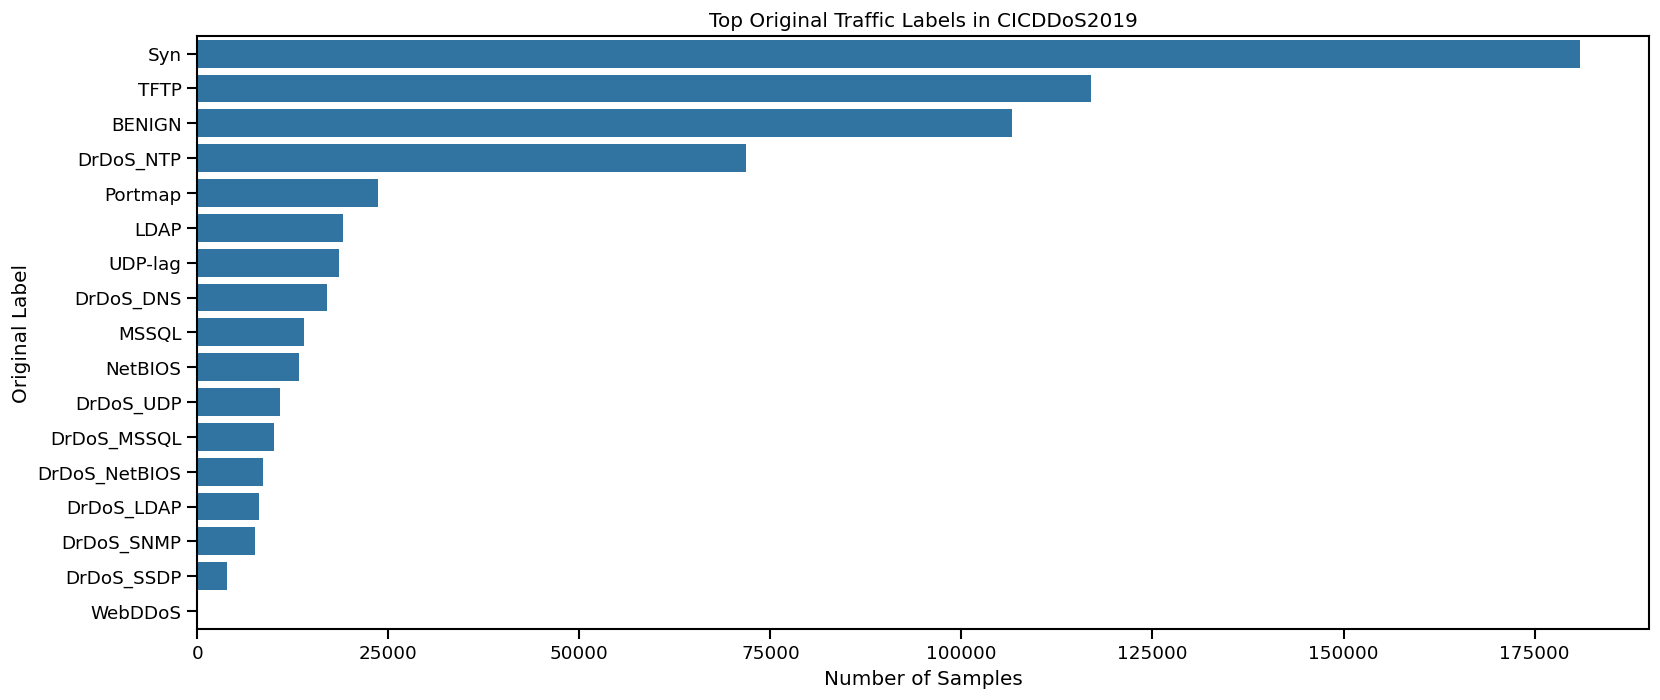

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/02_binary_class_distribution_bar.png


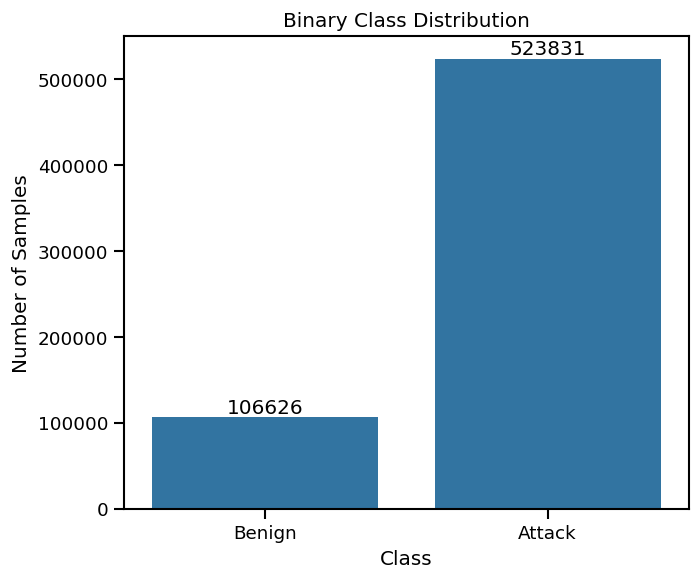

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/03_binary_class_distribution_pie.png


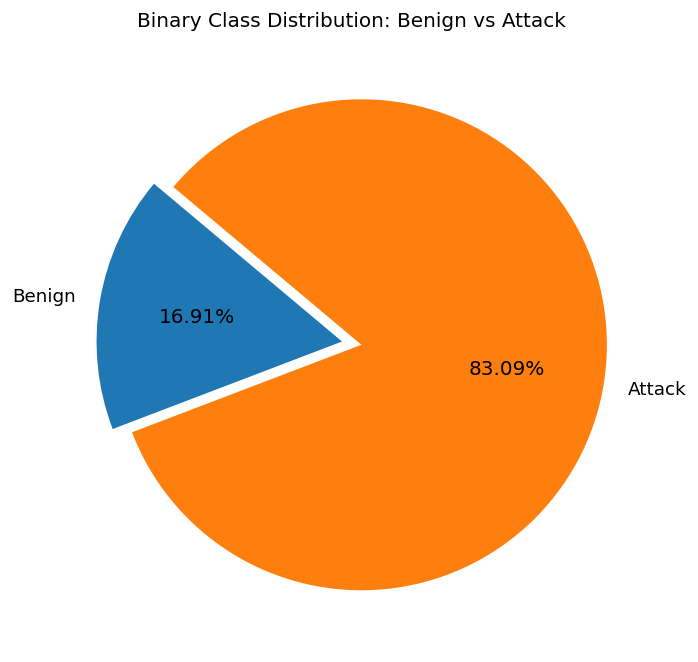

In [8]:
# ============================================================
# Plot original attack-type distribution and binary class distribution
# ============================================================

plt.figure(figsize=(14, 6))
label_counts_original = df[label_col].value_counts().head(25)
sns.barplot(x=label_counts_original.values, y=label_counts_original.index)
plt.title("Top Original Traffic Labels in CICDDoS2019")
plt.xlabel("Number of Samples")
plt.ylabel("Original Label")
save_fig("01_original_label_distribution_top25.png")
plt.show()

plt.figure(figsize=(6, 5))
binary_counts = df["Binary_Label"].value_counts().sort_index()
binary_names = ["Benign", "Attack"]
sns.barplot(x=binary_names, y=binary_counts.values)
plt.title("Binary Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
for i, v in enumerate(binary_counts.values):
    plt.text(i, v, str(v), ha="center", va="bottom")
save_fig("02_binary_class_distribution_bar.png")
plt.show()

plt.figure(figsize=(6, 6))
plt.pie(
    binary_counts.values,
    labels=binary_names,
    autopct="%1.2f%%",
    startangle=140,
    explode=[0.04, 0.04]
)
plt.title("Binary Class Distribution: Benign vs Attack")
save_fig("03_binary_class_distribution_pie.png")
plt.show()

Initial shape: (630457, 89)
Detected timestamp column: ' Timestamp'
Columns excluded from X: [' Label', 'Binary_Label', ' Source IP', ' Destination IP', 'Flow ID', 'SimillarHTTP', 'Unnamed: 0', ' Timestamp']

Top missing-value columns after conversion:


Flow Bytes/s                    22679
 Flow Packets/s                 22679
 Destination Port                   0
 Source Port                        0
 Protocol                           0
 Flow Duration                      0
Total Length of Fwd Packets         0
 Total Length of Bwd Packets        0
 Total Fwd Packets                  0
 Total Backward Packets             0
 Fwd Packet Length Min              0
 Fwd Packet Length Max              0
 Fwd Packet Length Mean             0
 Fwd Packet Length Std              0
 Bwd Packet Length Min              0
Bwd Packet Length Max               0
 Bwd Packet Length Std              0
 Bwd Packet Length Mean             0
 Flow IAT Mean                      0
 Flow IAT Std                       0
dtype: int64

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/04_missing_values_after_conversion.png


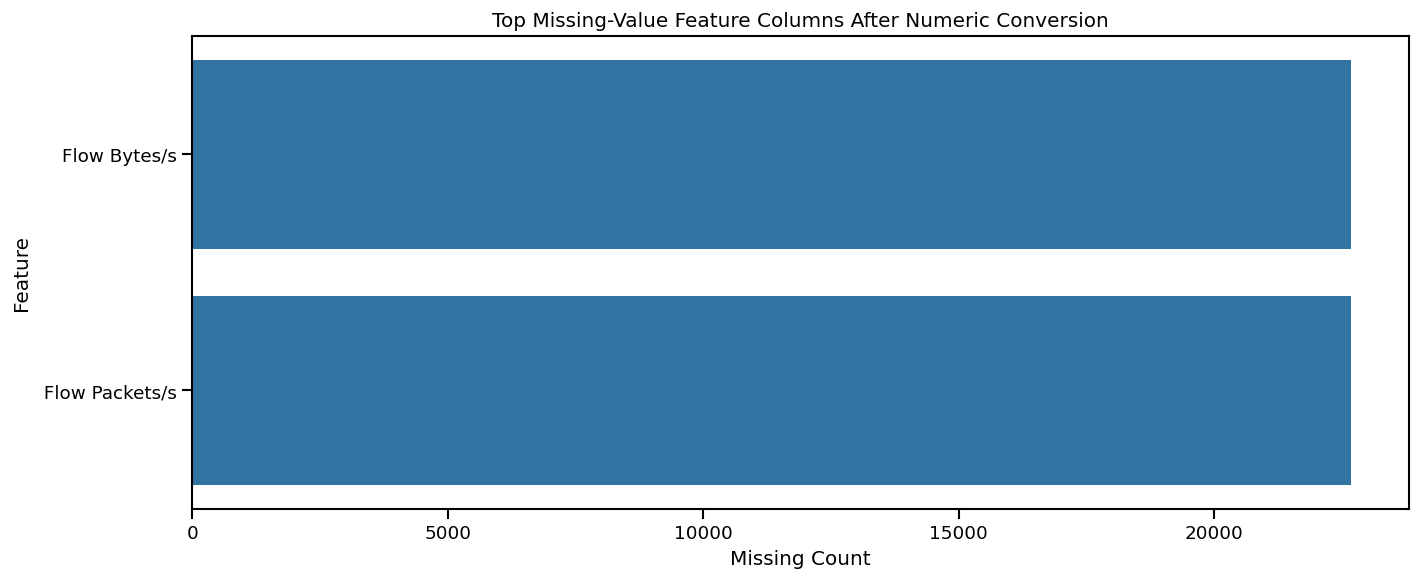


Final feature shape: (630457, 82)
Final label shape: (630457,)
Remaining missing values in X: 0
Memory reduced from 394.42 MB to 227.27 MB


In [9]:
# ============================================================
# Cleaning: replace infinity, convert numeric columns, handle missing values
# ============================================================

print("Initial shape:", df.shape)

# Replace numeric infinity
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Replace string infinity only in object columns to avoid memory-heavy df.astype(str)
object_cols = df.select_dtypes(include=["object"]).columns.tolist()
for col in object_cols:
    df[col] = df[col].replace(["inf", "infinity", "Inf", "Infinity", "INF", "INFINITY"], np.nan)

# Timestamp processing
timestamp_col = find_column_by_clean_name(df, "Timestamp")
if timestamp_col is not None:
    print("Detected timestamp column:", repr(timestamp_col))
    df[timestamp_col] = pd.to_datetime(df[timestamp_col], errors="coerce")
    df = df.sort_values(by=timestamp_col).reset_index(drop=True)
    df["Timestamp_Unix"] = df[timestamp_col].astype("int64") // 10**9
    df["Timestamp_Unix"] = df["Timestamp_Unix"].replace(-9223372037, np.nan)
else:
    print("No timestamp column found. Skipping timestamp conversion.")

# Drop non-numeric / identifier / leakage columns if they exist
drop_candidates = [
    label_col,
    "Binary_Label",
    " Source IP",
    "Source IP",
    " Destination IP",
    "Destination IP",
    "Flow ID",
    "SimillarHTTP",
    "Unnamed: 0",
]

if timestamp_col is not None:
    drop_candidates.append(timestamp_col)

drop_cols = [c for c in drop_candidates if c in df.columns]
print("Columns excluded from X:", drop_cols)

# Create feature dataframe
X_df = df.drop(columns=drop_cols, errors="ignore").copy()

# Add numeric timestamp feature if available
if "Timestamp_Unix" in df.columns:
    X_df["Timestamp_Unix"] = df["Timestamp_Unix"]

# Convert all feature columns to numeric
for col in X_df.columns:
    X_df[col] = pd.to_numeric(X_df[col], errors="coerce")

# Missing values after conversion
missing_counts = X_df.isna().sum().sort_values(ascending=False)
print("\nTop missing-value columns after conversion:")
display(missing_counts.head(20))

plt.figure(figsize=(12, 5))
top_missing = missing_counts[missing_counts > 0].head(30)
if len(top_missing) > 0:
    sns.barplot(x=top_missing.values, y=top_missing.index)
    plt.title("Top Missing-Value Feature Columns After Numeric Conversion")
    plt.xlabel("Missing Count")
    plt.ylabel("Feature")
else:
    plt.text(0.5, 0.5, "No missing values found after conversion", ha="center", va="center")
    plt.axis("off")
save_fig("04_missing_values_after_conversion.png")
plt.show()

# Fill missing values with medians. Remaining all-NaN columns are filled with 0.
feature_medians = X_df.median(numeric_only=True)
X_df = X_df.fillna(feature_medians)
X_df = X_df.fillna(0)

y = df["Binary_Label"].astype(np.int64).copy()

print("\nFinal feature shape:", X_df.shape)
print("Final label shape:", y.shape)
print("Remaining missing values in X:", X_df.isna().sum().sum())

X_df = reduce_memory_usage(X_df)

## 4. Exploratory Thesis Visualizations

In [10]:
# ============================================================
# Feature summary
# ============================================================

print("Feature dataframe information:")
display(X_df.describe().T.head(30))

feature_summary = pd.DataFrame({
    "feature": X_df.columns,
    "dtype": [str(X_df[c].dtype) for c in X_df.columns],
    "min": [X_df[c].min() for c in X_df.columns],
    "max": [X_df[c].max() for c in X_df.columns],
    "mean": [X_df[c].mean() for c in X_df.columns],
    "std": [X_df[c].std() for c in X_df.columns],
    "unique_values": [X_df[c].nunique() for c in X_df.columns]
})

display(feature_summary.head(20))
feature_summary.to_csv(OUTPUT_DIR / "feature_summary.csv", index=False)
print("Saved feature summary:", OUTPUT_DIR / "feature_summary.csv")

Feature dataframe information:


,count,mean,std,min,25%,50%,75%,max
Source Port,630457.0,3.229037e+04,2.581814e+04,0.00000,896.000000,36321.000000,5.925400e+04,6.553400e+04
Destination Port,630457.0,2.878124e+04,2.121011e+04,0.00000,8329.000000,28329.000000,4.784800e+04,6.553500e+04
Protocol,630457.0,1.216859e+01,5.499210e+00,0.00000,6.000000,17.000000,1.700000e+01,1.700000e+01
Flow Duration,630457.0,5.292439e+06,1.610161e+07,0.00000,1.000000,102.000000,9.264800e+04,1.200000e+08
Total Fwd Packets,630457.0,1.259917e+01,2.467771e+02,1.00000,2.000000,2.000000,8.000000e+00,9.975300e+04
Total Backward Packets,630457.0,1.823864e+00,4.703686e+01,0.00000,0.000000,0.000000,2.000000e+00,3.170000e+04
Total Length of Fwd Packets,630457.0,4.648604e+03,2.690114e+04,0.00000,12.000000,458.000000,2.944000e+03,1.526642e+07
Total Length of Bwd Packets,630457.0,1.135827e+03,8.847780e+04,0.00000,0.000000,0.000000,0.000000e+00,5.842950e+07
Fwd Packet Length Max,630457.0,3.329890e+02,4.280268e+02,0.00000,6.000000,229.000000,5.160000e+02,3.212000e+04
Fwd Packet Length Min,630457.0,2.983908e+02,4.057634e+02,0.00000,6.000000,80.000000,5.160000e+02,2.033000e+03


,feature,dtype,min,max,mean,std,unique_values
0,Source Port,int32,0.00000,6.553400e+04,3.229037e+04,2.581814e+04,60212
1,Destination Port,int32,0.00000,6.553500e+04,2.878124e+04,2.121011e+04,65400
2,Protocol,int8,0.00000,1.700000e+01,1.216859e+01,5.499210e+00,3
3,Flow Duration,int32,0.00000,1.200000e+08,5.292439e+06,1.610161e+07,142726
4,Total Fwd Packets,int32,1.00000,9.975300e+04,1.259917e+01,2.467771e+02,353
5,Total Backward Packets,int16,0.00000,3.170000e+04,1.823864e+00,4.703686e+01,441
6,Total Length of Fwd Packets,float32,0.00000,1.526642e+07,4.648604e+03,2.690114e+04,5695
7,Total Length of Bwd Packets,float32,0.00000,5.842950e+07,1.135827e+03,8.847780e+04,5850
8,Fwd Packet Length Max,float32,0.00000,3.212000e+04,3.329890e+02,4.280268e+02,2444
9,Fwd Packet Length Min,float32,0.00000,2.033000e+03,2.983908e+02,4.057634e+02,1036


Saved feature summary: /kaggle/working/cicddos2019_thesis_outputs/feature_summary.csv


Top features by absolute correlation with binary target:


,Correlation_with_Target
Inbound,0.866905
URG Flag Count,-0.606589
Down/Up Ratio,-0.481841
Bwd Packet Length Min,-0.440352
Destination Port,0.401450
CWE Flag Count,-0.372136
RST Flag Count,-0.361837
Fwd PSH Flags,-0.361837
Avg Bwd Segment Size,-0.350726
Bwd Packet Length Mean,-0.350726


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/05_top_feature_correlations_with_target.png


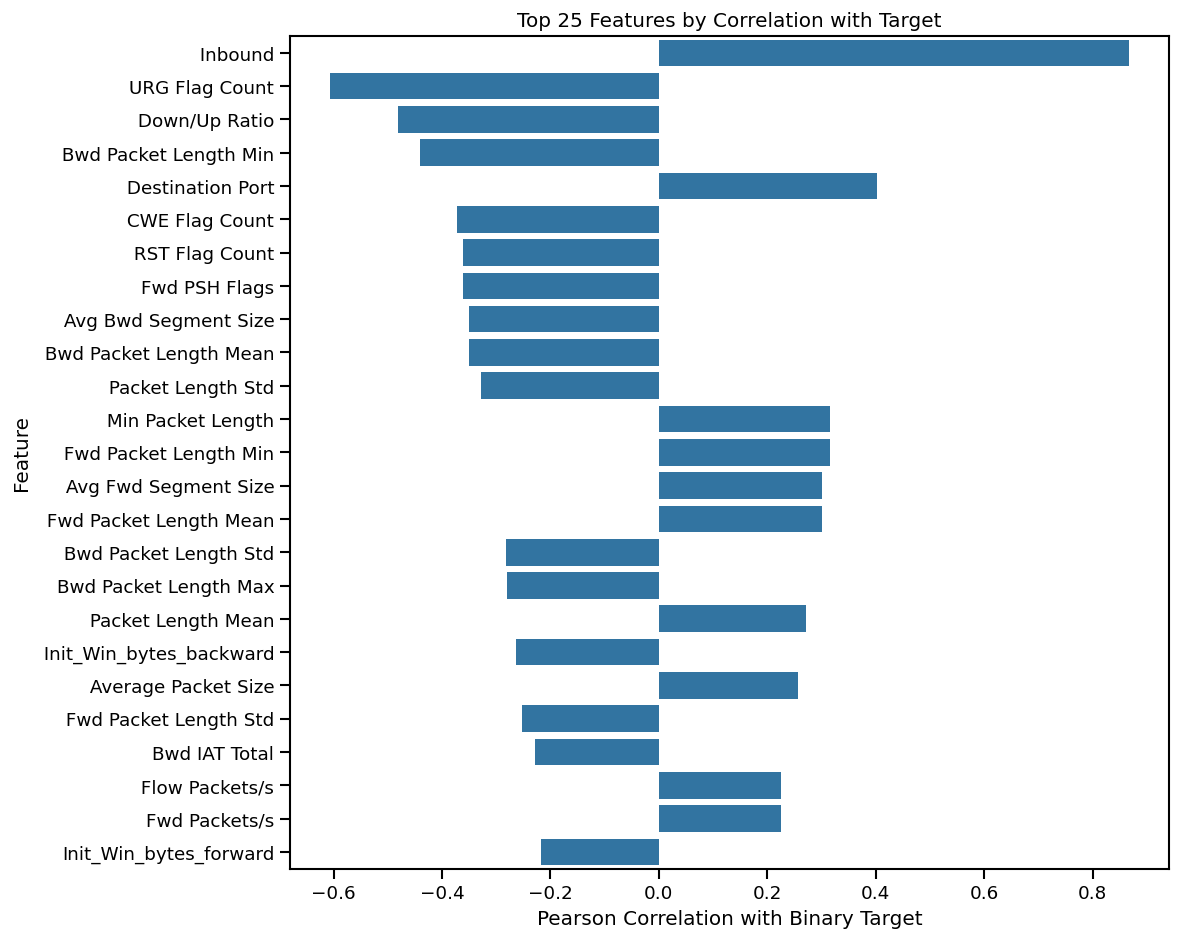

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/06_top_feature_correlation_heatmap.png


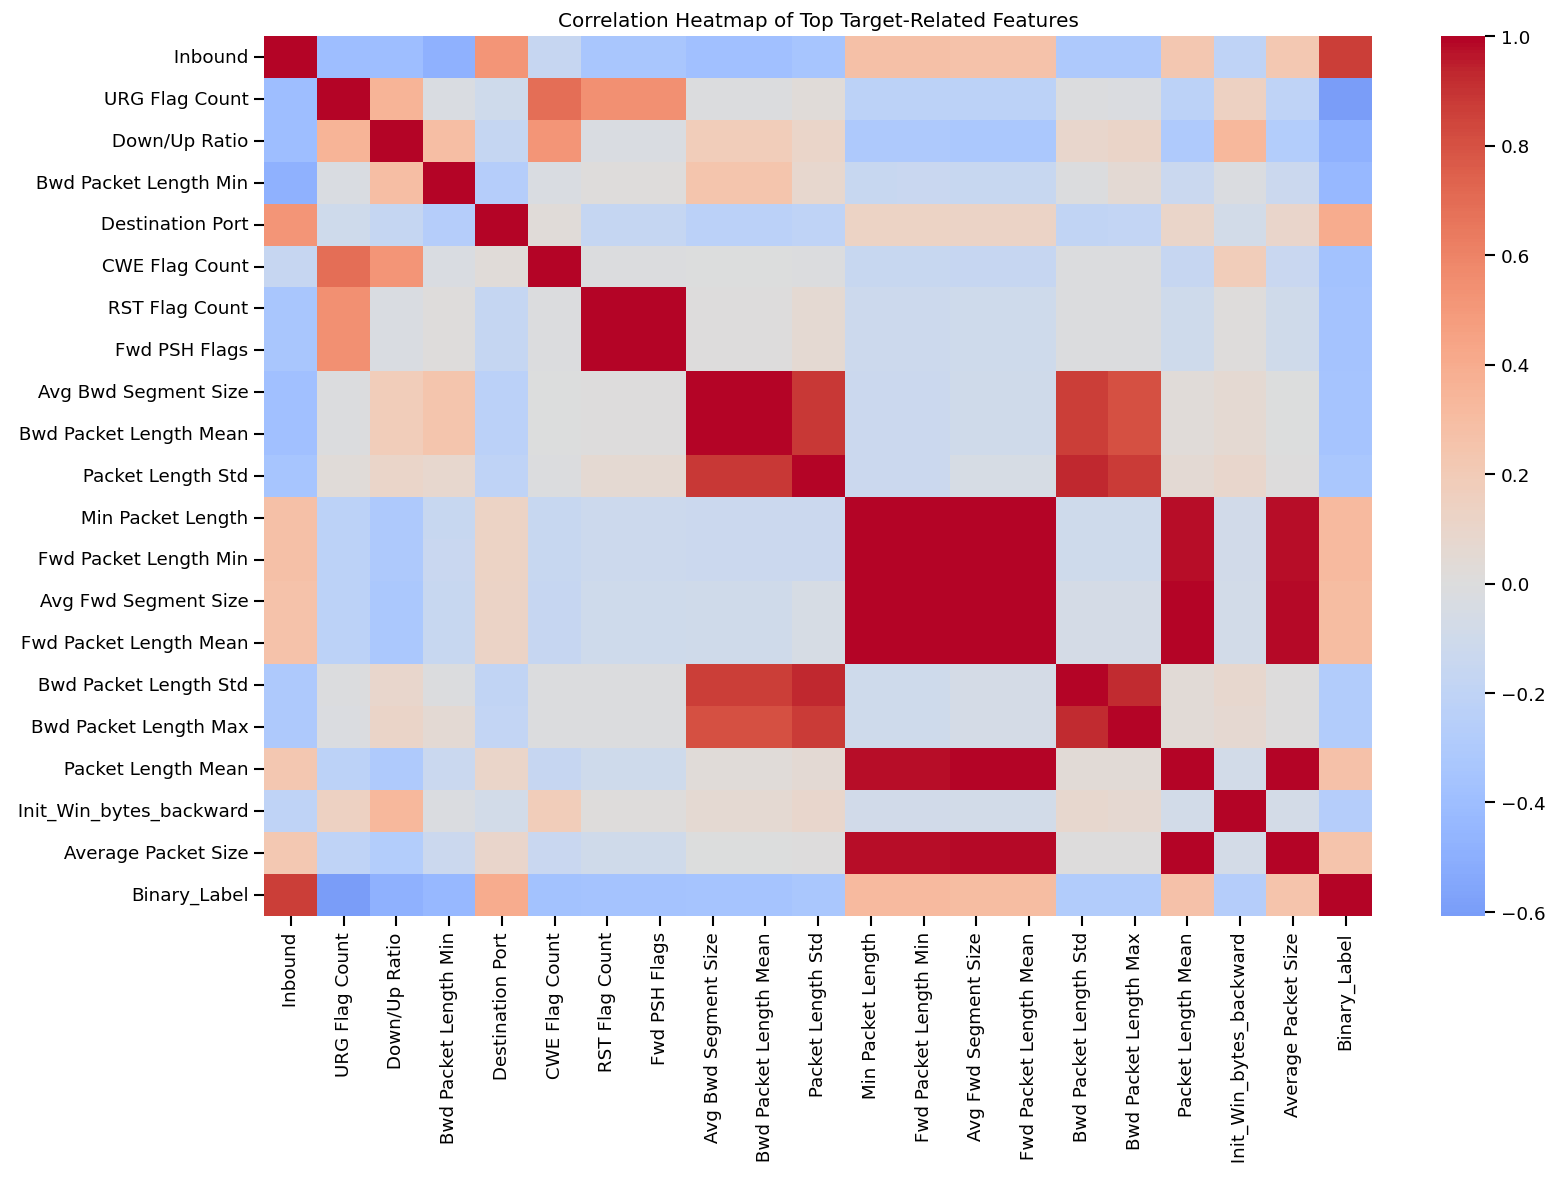

In [11]:
# ============================================================
# Correlation-based feature relevance plot
# ============================================================

eda_size = min(EDA_SAMPLE_SIZE, len(X_df))
eda_idx = np.random.RandomState(SEED).choice(len(X_df), size=eda_size, replace=False)

eda_df = X_df.iloc[eda_idx].copy()
eda_df["Binary_Label"] = y.iloc[eda_idx].values

corr_with_target = eda_df.corr(numeric_only=True)["Binary_Label"].drop("Binary_Label").sort_values(key=lambda s: s.abs(), ascending=False)

print("Top features by absolute correlation with binary target:")
display(corr_with_target.head(30).to_frame("Correlation_with_Target"))

plt.figure(figsize=(10, 8))
top_corr = corr_with_target.head(25)
sns.barplot(x=top_corr.values, y=top_corr.index)
plt.title("Top 25 Features by Correlation with Target")
plt.xlabel("Pearson Correlation with Binary Target")
plt.ylabel("Feature")
save_fig("05_top_feature_correlations_with_target.png")
plt.show()

# Correlation heatmap for top correlated features
top_features = corr_with_target.head(20).index.tolist()
plt.figure(figsize=(14, 10))
sns.heatmap(eda_df[top_features + ["Binary_Label"]].corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Top Target-Related Features")
save_fig("06_top_feature_correlation_heatmap.png")
plt.show()

## 5. Train / Validation / Test Split and Scaling

Train shape: (441319, 82) (441319,)
Validation shape: (126092, 82) (126092,)
Test shape: (63046, 82) (63046,)


,Split,Samples,Benign,Attack,Benign_%,Attack_%
0,Train,441319,74638,366681,16.9125,83.0875
1,Validation,126092,21325,104767,16.9123,83.0877
2,Test,63046,10663,52383,16.9130,83.0870


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/07_split_class_distribution.png


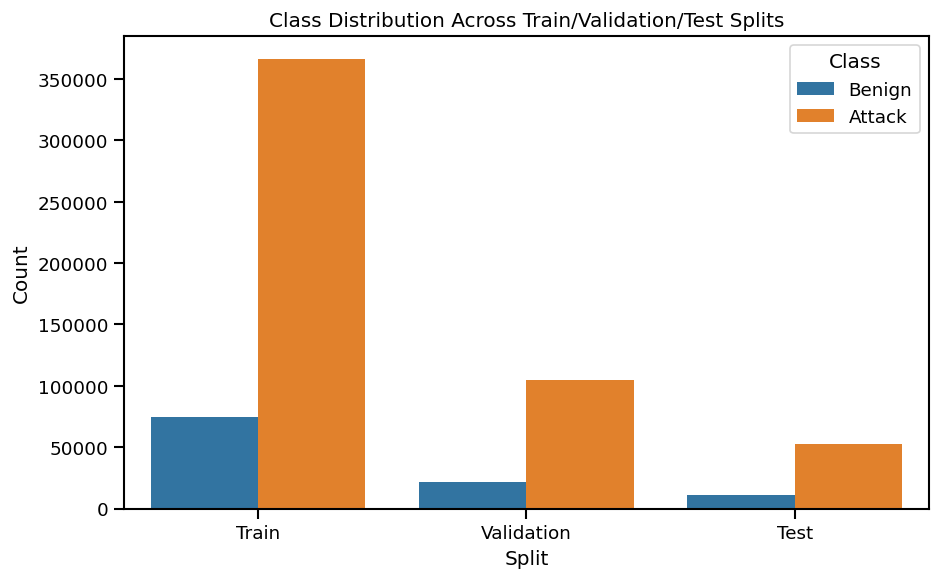

In [12]:
# ============================================================
# Split into train, validation, and test sets
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X_df,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=1/3,
    stratify=y_temp,
    random_state=SEED
)

print("Train shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Benign": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Attack": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
})
split_summary["Benign_%"] = (split_summary["Benign"] / split_summary["Samples"] * 100).round(4)
split_summary["Attack_%"] = (split_summary["Attack"] / split_summary["Samples"] * 100).round(4)

display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

plt.figure(figsize=(8, 5))
split_melted = split_summary.melt(id_vars="Split", value_vars=["Benign", "Attack"], var_name="Class", value_name="Count")
sns.barplot(data=split_melted, x="Split", y="Count", hue="Class")
plt.title("Class Distribution Across Train/Validation/Test Splits")
save_fig("07_split_class_distribution.png")
plt.show()

In [13]:
# ============================================================
# Scale features using MinMaxScaler
# ============================================================

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

num_features = X_train_scaled.shape[1]

print("Number of features:", num_features)
print("Scaled train shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

# Save feature names and scaler
pd.DataFrame({"feature": X_train.columns}).to_csv(OUTPUT_DIR / "selected_features.csv", index=False)

import joblib
joblib.dump(scaler, MODEL_DIR / "minmax_scaler.joblib")
print("Saved scaler:", MODEL_DIR / "minmax_scaler.joblib")

Number of features: 82
Scaled train shape: (441319, 82)
Scaled validation shape: (126092, 82)
Scaled test shape: (63046, 82)
Saved scaler: /kaggle/working/cicddos2019_thesis_outputs/models/minmax_scaler.joblib


## 6. Sequence Dataset for Deep Learning Models

The CNN, LSTM, and CNN-LSTM models all use the same fixed-length sequence input so the comparison is fair.

In [14]:
# ============================================================
# PyTorch sequence dataset and dataloaders
# ============================================================

class StreamingSequenceDataset(Dataset):
    def __init__(self, X, y, seq_len=100):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        self.seq_len = seq_len

    def __len__(self):
        return max(0, len(self.X) - self.seq_len + 1)

    def __getitem__(self, idx):
        end_idx = idx + self.seq_len
        x_seq = self.X[idx:end_idx]
        y_seq = self.y[end_idx - 1]
        return x_seq, y_seq


train_dataset = StreamingSequenceDataset(X_train_scaled, y_train_np, seq_len=SEQ_LEN)
val_dataset = StreamingSequenceDataset(X_val_scaled, y_val_np, seq_len=SEQ_LEN)
test_dataset = StreamingSequenceDataset(X_test_scaled, y_test_np, seq_len=SEQ_LEN)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Train sequence samples:", len(train_dataset))
print("Validation sequence samples:", len(val_dataset))
print("Test sequence samples:", len(test_dataset))

sample_x, sample_y = next(iter(train_loader))
print("Sample batch X shape:", sample_x.shape)
print("Sample batch y shape:", sample_y.shape)

Train sequence samples: 441220
Validation sequence samples: 125993
Test sequence samples: 62947
Sample batch X shape: torch.Size([64, 100, 82])
Sample batch y shape: torch.Size([64])


In [15]:
# ============================================================
# Class weights for imbalanced binary classification
# ============================================================

classes = np.array([0, 1])
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_np
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32).to(device)

print("Class weights:")
print("Benign:", class_weights_np[0])
print("Attack:", class_weights_np[1])

Class weights:
Benign: 2.9563962056861115
Attack: 0.6017751124274233


## 7. Model Architectures

This section defines:

1. **CNN-only model**: captures local sequential/temporal patterns.
2. **LSTM-only model**: captures long-range temporal dependencies.
3. **CNN-LSTM hybrid model**: CNN extracts local patterns first, then LSTM models sequential dependencies.

In [16]:
# ============================================================
# CNN-only, LSTM-only, and CNN-LSTM model architectures
# ============================================================

class CNNOnlyClassifier(nn.Module):
    def __init__(self, num_features, num_cnn_filters=64, dropout_rate=0.3):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels=num_features, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Conv1d(in_channels=num_cnn_filters, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_cnn_filters, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        # x: [batch, seq_len, num_features]
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        return self.classifier(x)


class LSTMOnlyClassifier(nn.Module):
    def __init__(self, num_features, lstm_hidden_size=100, lstm_layers=2, dropout_rate=0.3):
        super().__init__()
        effective_dropout = dropout_rate if lstm_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=num_features,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_layers,
            batch_first=True,
            dropout=effective_dropout
        )
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last_out = lstm_out[:, -1, :]
        return self.classifier(last_out)


class CNNLSTMClassifier(nn.Module):
    def __init__(self, num_features, num_cnn_filters=64, lstm_hidden_size=100, lstm_layers=2, dropout_rate=0.3):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels=num_features, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Conv1d(in_channels=num_cnn_filters, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU()
        )

        effective_dropout = dropout_rate if lstm_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=num_cnn_filters,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_layers,
            batch_first=True,
            dropout=effective_dropout
        )

        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        # x: [batch, seq_len, num_features]
        x = x.permute(0, 2, 1)       # [batch, num_features, seq_len]
        x = self.cnn(x)              # [batch, filters, seq_len]
        x = x.permute(0, 2, 1)       # [batch, seq_len, filters]
        lstm_out, _ = self.lstm(x)
        last_out = lstm_out[:, -1, :]
        return self.classifier(last_out)


def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


cnn_preview = CNNOnlyClassifier(num_features=num_features)
lstm_preview = LSTMOnlyClassifier(num_features=num_features)
hybrid_preview = CNNLSTMClassifier(num_features=num_features)

print("CNN-only trainable parameters:", count_trainable_params(cnn_preview))
print("LSTM-only trainable parameters:", count_trainable_params(lstm_preview))
print("CNN-LSTM trainable parameters:", count_trainable_params(hybrid_preview))

CNN-only trainable parameters: 32706
LSTM-only trainable parameters: 160994
CNN-LSTM trainable parameters: 182210


## 8. Training and Evaluation Utilities

In [17]:
# ============================================================
# Training and evaluation functions for deep learning models
# ============================================================

def calculate_metrics(y_true, y_pred, y_score, model_name):
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

    try:
        metrics["ROC-AUC"] = roc_auc_score(y_true, y_score)
    except Exception:
        metrics["ROC-AUC"] = np.nan

    try:
        metrics["PR-AUC"] = average_precision_score(y_true, y_score)
    except Exception:
        metrics["PR-AUC"] = np.nan

    return metrics


def evaluate_deep_model(model, loader, model_name="Deep Model", make_plots=True, max_batches=None):
    model.eval()
    all_labels = []
    all_preds = []
    all_scores = []

    iterator = enumerate(loader)
    if max_batches is not None:
        iterator = zip(range(max_batches), loader)

    with torch.no_grad():
        for batch_idx, (batch_x, batch_y) in iterator:
            batch_x = batch_x.to(device, non_blocking=True)
            outputs = model(batch_x)
            probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
            preds = torch.argmax(outputs, dim=1).cpu().numpy()

            all_scores.extend(probs)
            all_preds.extend(preds)
            all_labels.extend(batch_y.numpy())

            if max_batches is not None and batch_idx + 1 >= max_batches:
                break

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_score = np.array(all_scores)

    metrics = calculate_metrics(y_true, y_pred, y_score, model_name)

    if make_plots:
        print(f"\nClassification Report - {model_name}")
        print(classification_report(y_true, y_pred, target_names=["Benign", "Attack"], zero_division=0))
        plot_confusion_matrix(y_true, y_pred, model_name)
        plot_roc_curve(y_true, y_score, model_name)
        plot_precision_recall_curve(y_true, y_score, model_name)

    return metrics, y_true, y_pred, y_score


def run_one_epoch(model, loader, criterion, optimizer=None, max_batches=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    iterator = enumerate(loader)
    if max_batches is not None:
        iterator = zip(range(max_batches), loader)

    with torch.set_grad_enabled(is_train):
        for batch_idx, (batch_x, batch_y) in iterator:
            batch_x = batch_x.to(device, non_blocking=True)
            batch_y = batch_y.to(device, non_blocking=True)

            if is_train:
                optimizer.zero_grad()

            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * batch_x.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)

            if max_batches is not None and batch_idx + 1 >= max_batches:
                break

    avg_loss = total_loss / max(total, 1)
    avg_acc = correct / max(total, 1)
    return avg_loss, avg_acc


def train_deep_model(
    model,
    model_name,
    train_loader,
    val_loader,
    num_epochs=10,
    learning_rate=1e-3,
    weight_decay=0.0,
    max_train_batches=None,
    max_val_batches=None
):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_f1": []
    }

    best_val_f1 = -1
    best_state = None

    for epoch in range(num_epochs):
        train_loss, train_acc = run_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            max_batches=max_train_batches
        )

        val_loss, val_acc = run_one_epoch(
            model,
            val_loader,
            criterion,
            optimizer=None,
            max_batches=max_val_batches
        )

        # Quick validation F1
        val_metrics, _, _, _ = evaluate_deep_model(
            model,
            val_loader,
            model_name=f"{model_name} Validation",
            make_plots=False,
            max_batches=max_val_batches
        )

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_metrics["F1 Score"])

        current_val_f1 = val_metrics["F1 Score"]

        if current_val_f1 > best_val_f1:
            best_val_f1 = current_val_f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(
            f"{model_name} | Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | Val F1: {current_val_f1:.4f}"
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    history_df = pd.DataFrame(history)
    history_df.to_csv(OUTPUT_DIR / f"{model_name.replace(' ', '_').lower()}_history.csv", index=False)

    return model, history_df


def plot_history(history_df, model_name):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train Loss")
    plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")
    plt.title(f"{model_name} Loss Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(history_df["epoch"], history_df["train_acc"], marker="o", label="Train Accuracy")
    plt.plot(history_df["epoch"], history_df["val_acc"], marker="o", label="Validation Accuracy")
    plt.plot(history_df["epoch"], history_df["val_f1"], marker="o", label="Validation F1")
    plt.title(f"{model_name} Accuracy/F1 Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True, alpha=0.3)

    save_fig(f"{model_name.replace(' ', '_').lower()}_training_curves.png")
    plt.show()


def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Benign", "Attack"],
        yticklabels=["Benign", "Attack"]
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    save_fig(f"{model_name.replace(' ', '_').lower()}_confusion_matrix.png")
    plt.show()


def plot_roc_curve(y_true, y_score, model_name):
    try:
        fpr, tpr, _ = roc_curve(y_true, y_score)
        auc_value = roc_auc_score(y_true, y_score)

        plt.figure(figsize=(6, 5))
        plt.plot(fpr, tpr, label=f"ROC-AUC = {auc_value:.4f}")
        plt.plot([0, 1], [0, 1], linestyle="--")
        plt.title(f"ROC Curve - {model_name}")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_fig(f"{model_name.replace(' ', '_').lower()}_roc_curve.png")
        plt.show()
    except Exception as e:
        print(f"Could not plot ROC curve for {model_name}: {e}")


def plot_precision_recall_curve(y_true, y_score, model_name):
    try:
        precision, recall, _ = precision_recall_curve(y_true, y_score)
        pr_auc = average_precision_score(y_true, y_score)

        plt.figure(figsize=(6, 5))
        plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}")
        plt.title(f"Precision-Recall Curve - {model_name}")
        plt.xlabel("Recall")
        plt.ylabel("Precision")
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_fig(f"{model_name.replace(' ', '_').lower()}_precision_recall_curve.png")
        plt.show()
    except Exception as e:
        print(f"Could not plot Precision-Recall curve for {model_name}: {e}")

## 9. Train Standalone CNN Model

This model is trained **without Bayesian optimization**. It is used to show what CNN can do alone.

CNNOnlyClassifier(
  (cnn): Sequential(
    (0): Conv1d(82, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 32706
CNN Only | Epoch 1/10 | Train Loss: 0.0608 | Val Loss: 0.0131 | Train Acc: 0.9795 | Val Acc: 0.9985 | Val F1: 0.9991
CNN Only | Epoch 2/10 | Train Loss: 0.0135 | Val Loss: 0.0063 | Train Acc: 0.9973 | Val Acc: 0.9990 | Val F1: 0.9994
CNN Only | Epoc

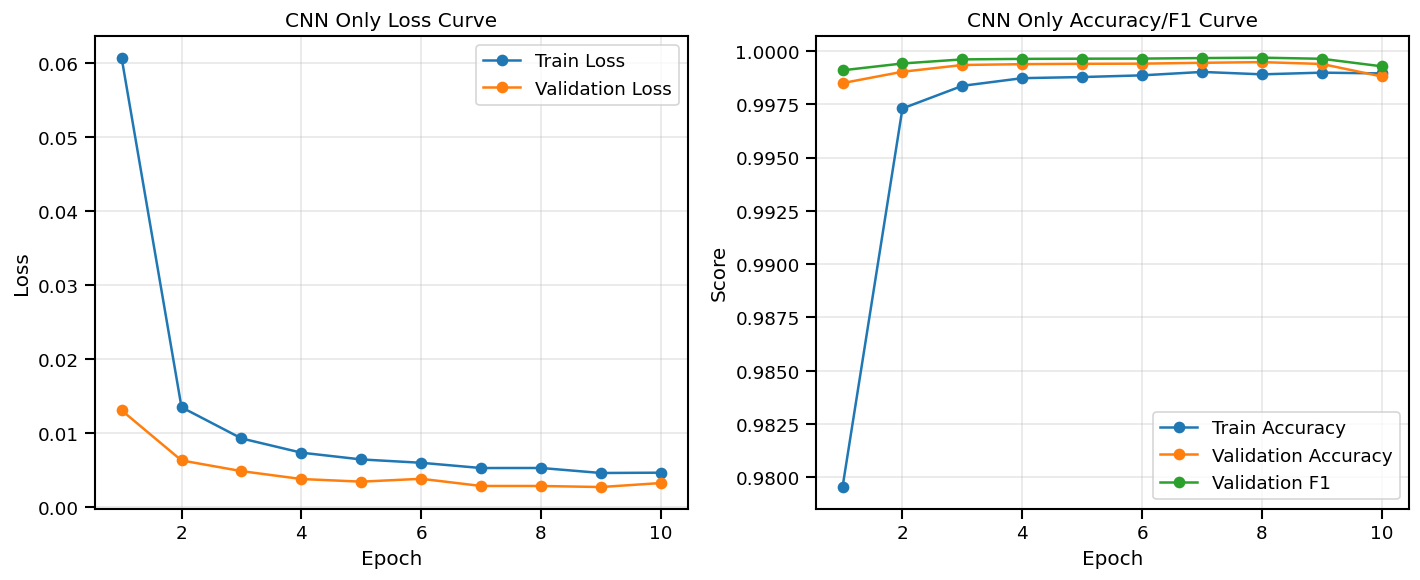

Saved CNN-only model: /kaggle/working/cicddos2019_thesis_outputs/models/cnn_only_model.pth


In [18]:
# ============================================================
# Train CNN-only baseline
# ============================================================

cnn_model = CNNOnlyClassifier(
    num_features=num_features,
    num_cnn_filters=64,
    dropout_rate=0.3
)

print(cnn_model)
print("Trainable parameters:", count_trainable_params(cnn_model))

cnn_model, cnn_history = train_deep_model(
    model=cnn_model,
    model_name="CNN Only",
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=BASELINE_DEEP_EPOCHS,
    learning_rate=1e-3
)

plot_history(cnn_history, "CNN Only")

torch.save(cnn_model.state_dict(), MODEL_DIR / "cnn_only_model.pth")
print("Saved CNN-only model:", MODEL_DIR / "cnn_only_model.pth")


Classification Report - CNN Only
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     10650
      Attack       1.00      1.00      1.00     52297

    accuracy                           1.00     62947
   macro avg       1.00      1.00      1.00     62947
weighted avg       1.00      1.00      1.00     62947

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/cnn_only_confusion_matrix.png


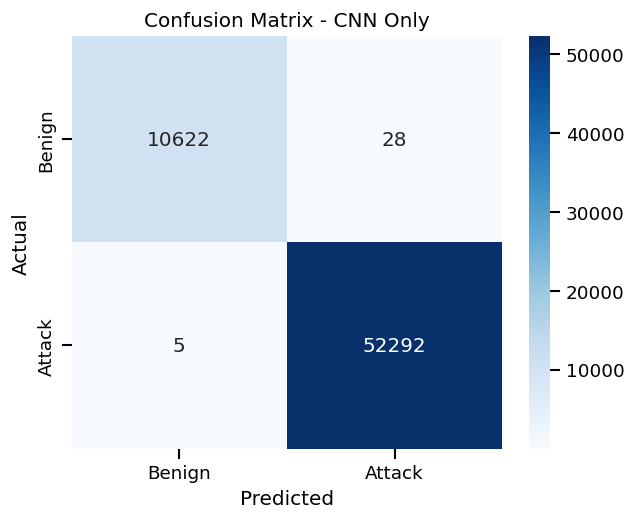

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/cnn_only_roc_curve.png


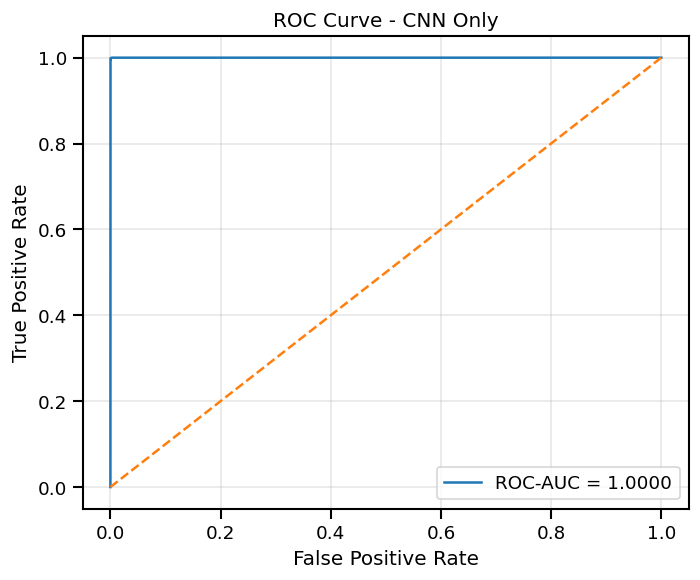

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/cnn_only_precision_recall_curve.png


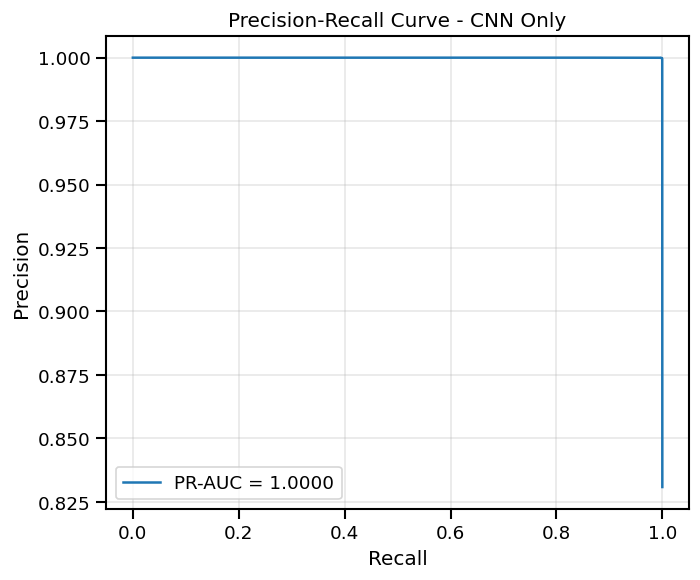

CNN-only test metrics:


,Model,Accuracy,Precision,Recall,F1 Score,MCC,ROC-AUC,PR-AUC
0,CNN Only,0.999476,0.999465,0.999904,0.999685,0.998134,0.999994,0.999999


In [19]:
# ============================================================
# Evaluate CNN-only baseline
# ============================================================

cnn_results, cnn_y_true, cnn_y_pred, cnn_y_score = evaluate_deep_model(
    cnn_model,
    test_loader,
    model_name="CNN Only",
    make_plots=True
)

print("CNN-only test metrics:")
display(pd.DataFrame([cnn_results]))

## 10. Train Standalone LSTM Model

This model is trained **without Bayesian optimization**. It is used to show what LSTM can do alone.

LSTMOnlyClassifier(
  (lstm): LSTM(82, 100, num_layers=2, batch_first=True, dropout=0.3)
  (classifier): Sequential(
    (0): Linear(in_features=100, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 160994
LSTM Only | Epoch 1/10 | Train Loss: 0.0300 | Val Loss: 0.0063 | Train Acc: 0.9897 | Val Acc: 0.9992 | Val F1: 0.9995
LSTM Only | Epoch 2/10 | Train Loss: 0.0075 | Val Loss: 0.0044 | Train Acc: 0.9988 | Val Acc: 0.9991 | Val F1: 0.9995
LSTM Only | Epoch 3/10 | Train Loss: 0.0056 | Val Loss: 0.0037 | Train Acc: 0.9991 | Val Acc: 0.9994 | Val F1: 0.9997
LSTM Only | Epoch 4/10 | Train Loss: 0.0044 | Val Loss: 0.0038 | Train Acc: 0.9991 | Val Acc: 0.9995 | Val F1: 0.9997
LSTM Only | Epoch 5/10 | Train Loss: 0.0035 | Val Loss: 0.0028 | Train Acc: 0.9992 | Val Acc: 0.9988 | Val F1: 0.9993
LSTM Only | Epoch 6/10 | Train Loss: 0.0032 | Val Loss: 0.0021 | Train Acc: 0.9992 

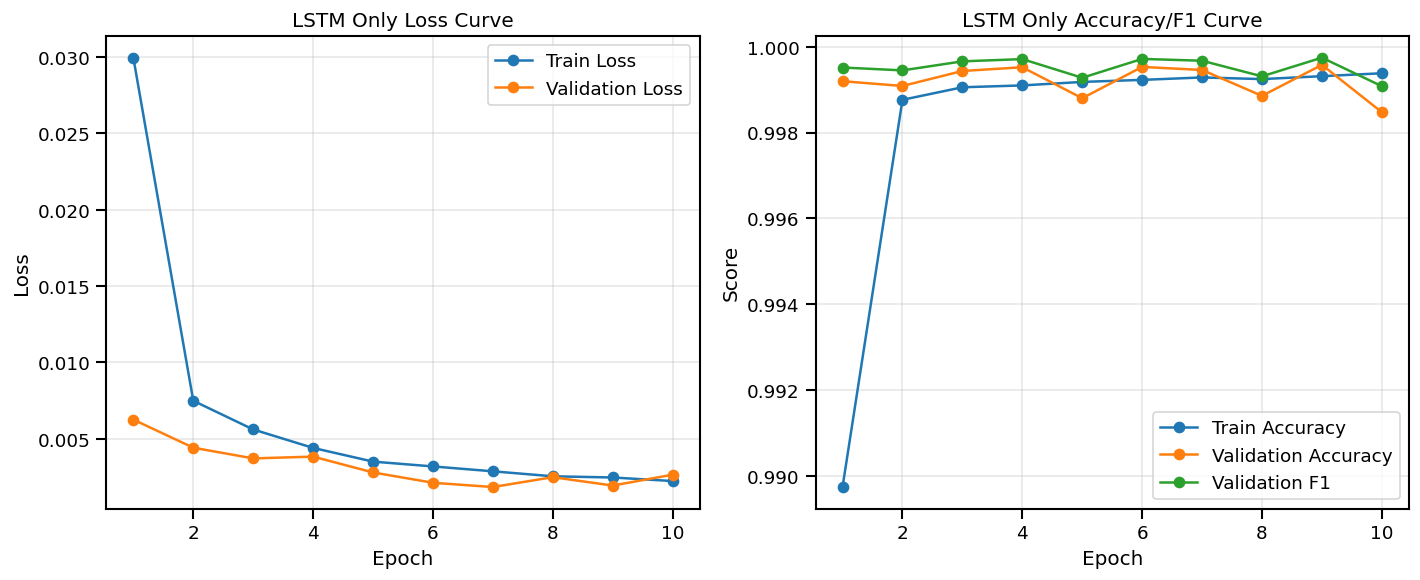

Saved LSTM-only model: /kaggle/working/cicddos2019_thesis_outputs/models/lstm_only_model.pth


In [20]:
# ============================================================
# Train LSTM-only baseline
# ============================================================

lstm_model = LSTMOnlyClassifier(
    num_features=num_features,
    lstm_hidden_size=100,
    lstm_layers=2,
    dropout_rate=0.3
)

print(lstm_model)
print("Trainable parameters:", count_trainable_params(lstm_model))

lstm_model, lstm_history = train_deep_model(
    model=lstm_model,
    model_name="LSTM Only",
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=BASELINE_DEEP_EPOCHS,
    learning_rate=1e-3
)

plot_history(lstm_history, "LSTM Only")

torch.save(lstm_model.state_dict(), MODEL_DIR / "lstm_only_model.pth")
print("Saved LSTM-only model:", MODEL_DIR / "lstm_only_model.pth")


Classification Report - LSTM Only
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     10650
      Attack       1.00      1.00      1.00     52297

    accuracy                           1.00     62947
   macro avg       1.00      1.00      1.00     62947
weighted avg       1.00      1.00      1.00     62947

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/lstm_only_confusion_matrix.png


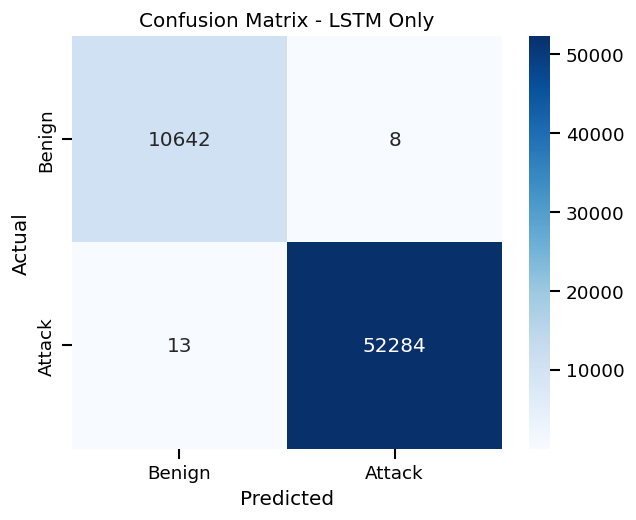

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/lstm_only_roc_curve.png


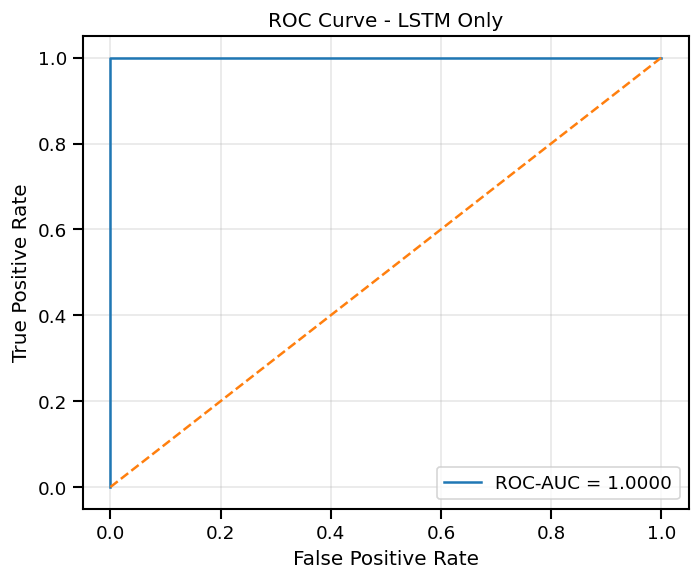

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/lstm_only_precision_recall_curve.png


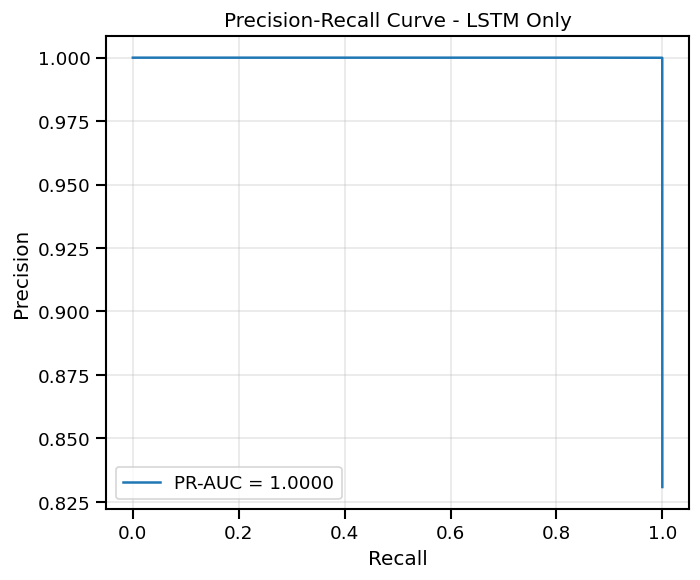

LSTM-only test metrics:


,Model,Accuracy,Precision,Recall,F1 Score,MCC,ROC-AUC,PR-AUC
0,LSTM Only,0.999666,0.999847,0.999751,0.999799,0.998814,0.999999,1.0


In [21]:
# ============================================================
# Evaluate LSTM-only baseline
# ============================================================

lstm_results, lstm_y_true, lstm_y_pred, lstm_y_score = evaluate_deep_model(
    lstm_model,
    test_loader,
    model_name="LSTM Only",
    make_plots=True
)

print("LSTM-only test metrics:")
display(pd.DataFrame([lstm_results]))

## 11. Bayesian Optimization for CNN-LSTM

This section optimizes only the main hybrid CNN-LSTM model.

The visualizations are created using **Matplotlib**, not Plotly, so they show reliably in Kaggle notebooks.

In [22]:
# ============================================================
# Optuna objective function for CNN-LSTM
# ============================================================

def objective(trial):
    num_cnn_filters = trial.suggest_categorical("num_cnn_filters", [32, 64, 128])
    lstm_hidden_size = trial.suggest_categorical("lstm_hidden_size", [50, 100, 150])
    lstm_layers = trial.suggest_int("lstm_layers", 1, 3)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)

    model = CNNLSTMClassifier(
        num_features=num_features,
        num_cnn_filters=num_cnn_filters,
        lstm_hidden_size=lstm_hidden_size,
        lstm_layers=lstm_layers,
        dropout_rate=dropout_rate
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    for epoch in range(OPTUNA_EPOCHS_PER_TRIAL):
        train_loss, train_acc = run_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            max_batches=MAX_OPTUNA_TRAIN_BATCHES_PER_EPOCH
        )

        val_metrics, _, _, _ = evaluate_deep_model(
            model,
            val_loader,
            model_name=f"Trial {trial.number}",
            make_plots=False,
            max_batches=MAX_OPTUNA_VAL_BATCHES
        )

        trial.report(val_metrics["F1 Score"], step=epoch)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return val_metrics["F1 Score"]

In [23]:
# ============================================================
# Run Bayesian optimization
# ============================================================

optuna.logging.set_verbosity(optuna.logging.INFO)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2)
)

study.optimize(objective, n_trials=OPTUNA_TRIALS)

print("Best trial value:", study.best_trial.value)
print("Best hyperparameters:")
print(study.best_trial.params)

with open(OUTPUT_DIR / "best_cnn_lstm_hyperparameters.json", "w") as f:
    json.dump(study.best_trial.params, f, indent=4)

trials_df = study.trials_dataframe()
display(trials_df)
trials_df.to_csv(OUTPUT_DIR / "optuna_trials.csv", index=False)

print("Saved Optuna trial history:", OUTPUT_DIR / "optuna_trials.csv")

[I 2026-06-03 16:47:16,891] A new study created in memory with name: no-name-6c5db4c8-e804-409f-bd25-135c66169189
[I 2026-06-03 16:47:24,122] Trial 0 finished with value: 0.9923519969785667 and parameters: {'num_cnn_filters': 64, 'lstm_hidden_size': 50, 'lstm_layers': 1, 'learning_rate': 0.005399484409787433, 'dropout_rate': 0.34044600469728353, 'weight_decay': 0.000133112160807369}. Best is trial 0 with value: 0.9923519969785667.
[I 2026-06-03 16:47:31,464] Trial 1 finished with value: 0.9981234753237005 and parameters: {'num_cnn_filters': 64, 'lstm_hidden_size': 50, 'lstm_layers': 1, 'learning_rate': 0.0011207606211860567, 'dropout_rate': 0.2727780074568463, 'weight_decay': 7.4763120622522945e-06}. Best is trial 1 with value: 0.9981234753237005.
[I 2026-06-03 16:47:49,817] Trial 2 finished with value: 0.9938696595303216 and parameters: {'num_cnn_filters': 32, 'lstm_hidden_size': 150, 'lstm_layers': 1, 'learning_rate': 0.0010677482709481358, 'dropout_rate': 0.33696582754481696, 'weigh

Best trial value: 0.9987812880847473
Best hyperparameters:
{'num_cnn_filters': 64, 'lstm_hidden_size': 50, 'lstm_layers': 1, 'learning_rate': 0.001096821720752952, 'dropout_rate': 0.31868411173731187, 'weight_decay': 3.5856126103453987e-06}


,number,value,datetime_start,datetime_complete,duration,params_dropout_rate,params_learning_rate,params_lstm_hidden_size,params_lstm_layers,params_num_cnn_filters,params_weight_decay,state
0,0,0.992352,2026-06-03 16:47:16.892818,2026-06-03 16:47:24.122873,0 days 00:00:07.230055,0.340446,0.005399,50,1,64,0.000133,COMPLETE
1,1,0.998123,2026-06-03 16:47:24.124337,2026-06-03 16:47:31.464162,0 days 00:00:07.339825,0.272778,0.001121,50,1,64,0.000007,COMPLETE
2,2,0.993870,2026-06-03 16:47:31.465228,2026-06-03 16:47:49.817536,0 days 00:00:18.352308,0.336966,0.001068,150,1,32,0.000001,COMPLETE
3,3,0.994822,2026-06-03 16:47:49.818466,2026-06-03 16:47:57.259452,0 days 00:00:07.440986,0.373693,0.000157,100,1,32,0.000021,COMPLETE
4,4,0.998781,2026-06-03 16:47:57.260485,2026-06-03 16:48:04.469199,0 days 00:00:07.208714,0.318684,0.001097,50,1,64,0.000004,COMPLETE
5,5,0.995201,2026-06-03 16:48:04.470275,2026-06-03 16:48:15.510247,0 days 00:00:11.039972,0.118091,0.000247,150,1,32,0.000009,PRUNED
6,6,0.995105,2026-06-03 16:48:15.511102,2026-06-03 16:48:27.352602,0 days 00:00:11.841500,0.129820,0.004022,150,1,128,0.000913,PRUNED
7,7,0.994917,2026-06-03 16:48:27.353545,2026-06-03 16:48:32.385904,0 days 00:00:05.032359,0.243386,0.000141,50,3,32,0.000002,PRUNED
8,8,0.995010,2026-06-03 16:48:32.387246,2026-06-03 16:48:59.227692,0 days 00:00:26.840446,0.454885,0.001884,150,3,32,0.000026,PRUNED
9,9,0.998028,2026-06-03 16:48:59.228623,2026-06-03 16:49:10.127866,0 days 00:00:10.899243,0.110168,0.000716,100,2,128,0.000002,COMPLETE


Saved Optuna trial history: /kaggle/working/cicddos2019_thesis_outputs/optuna_trials.csv


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_01_optimization_history.png


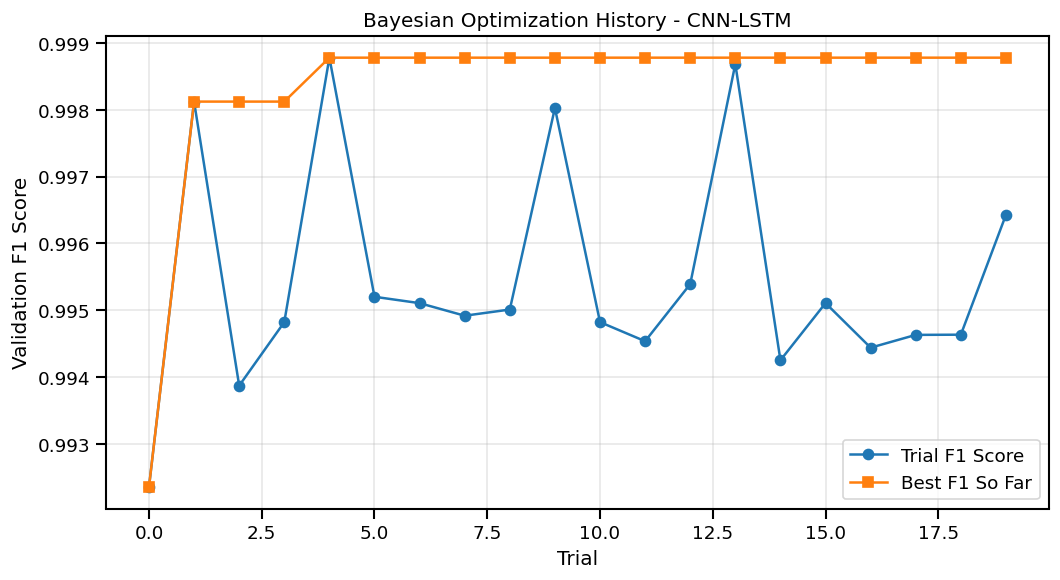

,Parameter,Importance
0,dropout_rate,0.588469
1,weight_decay,0.157984
2,num_cnn_filters,0.147933
3,lstm_layers,0.061446
4,learning_rate,0.025889
5,lstm_hidden_size,0.018279


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_02_param_importance.png


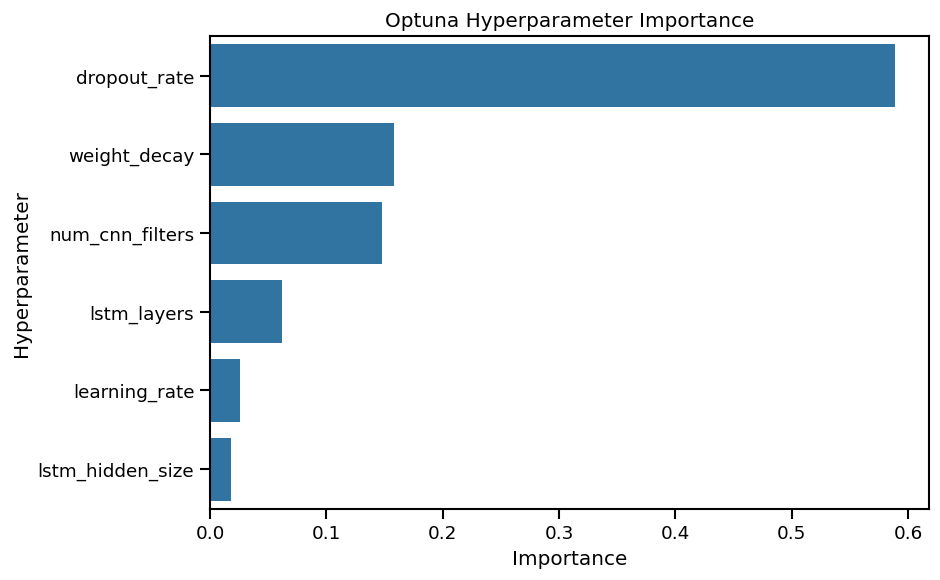

,trial,value,num_cnn_filters,lstm_hidden_size,lstm_layers,learning_rate,dropout_rate,weight_decay
0,0,0.992352,64,50,1,0.005399,0.340446,0.000133
1,1,0.998123,64,50,1,0.001121,0.272778,0.000007
2,2,0.993870,32,150,1,0.001068,0.336966,0.000001
3,3,0.994822,32,100,1,0.000157,0.373693,0.000021
4,4,0.998781,64,50,1,0.001097,0.318684,0.000004


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_03_slice_num_cnn_filters.png


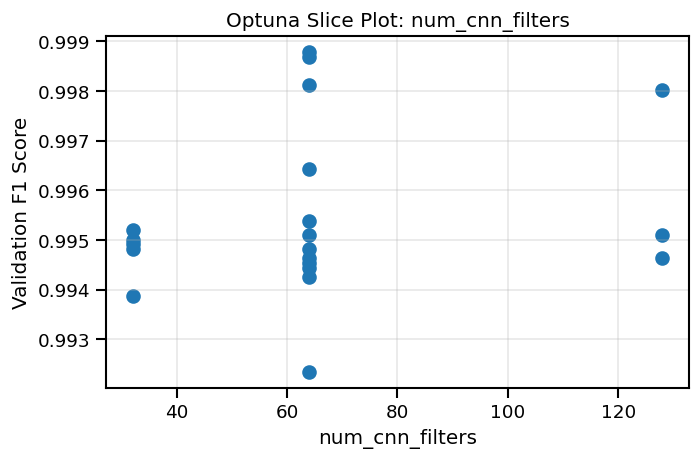

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_03_slice_lstm_hidden_size.png


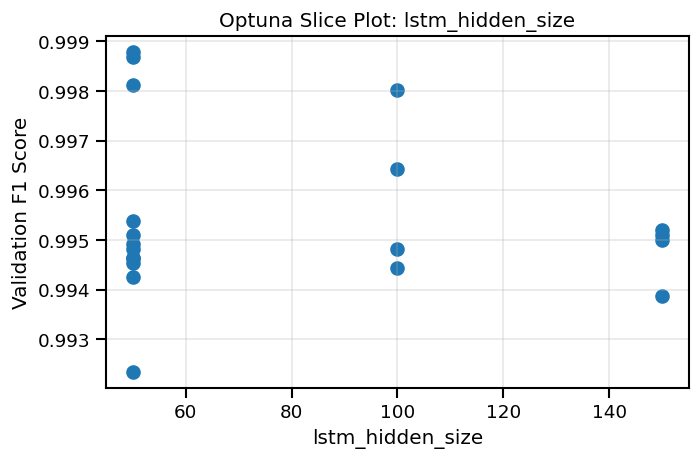

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_03_slice_lstm_layers.png


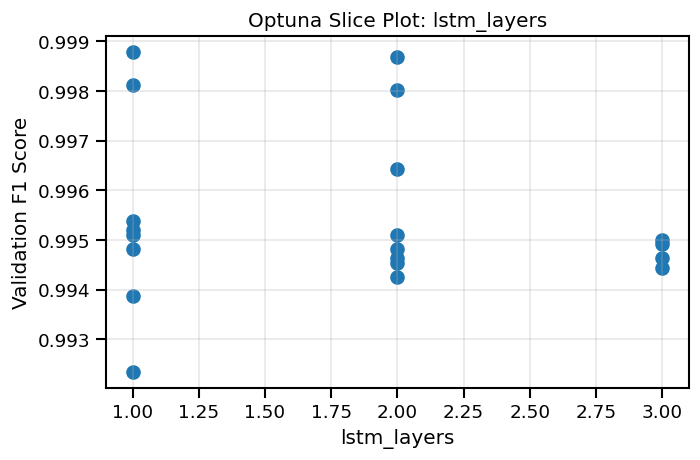

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_03_slice_learning_rate.png


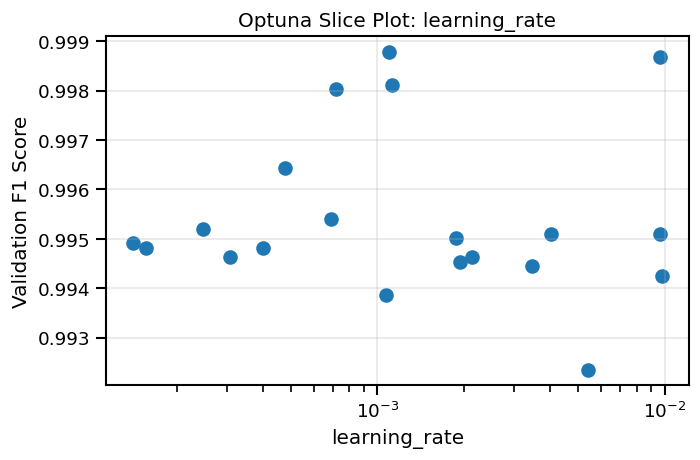

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_03_slice_dropout_rate.png


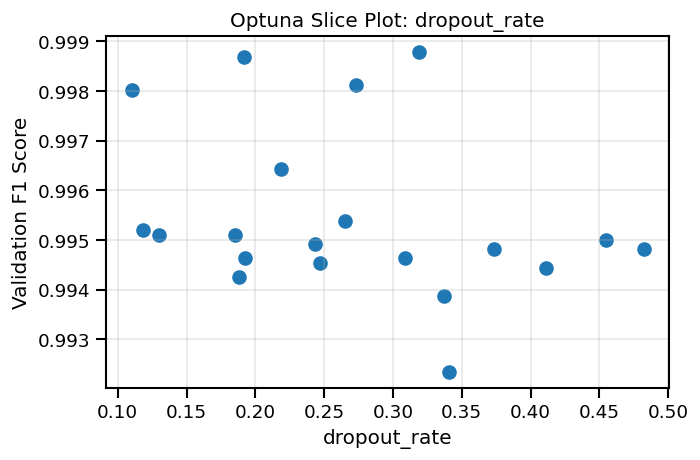

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_03_slice_weight_decay.png


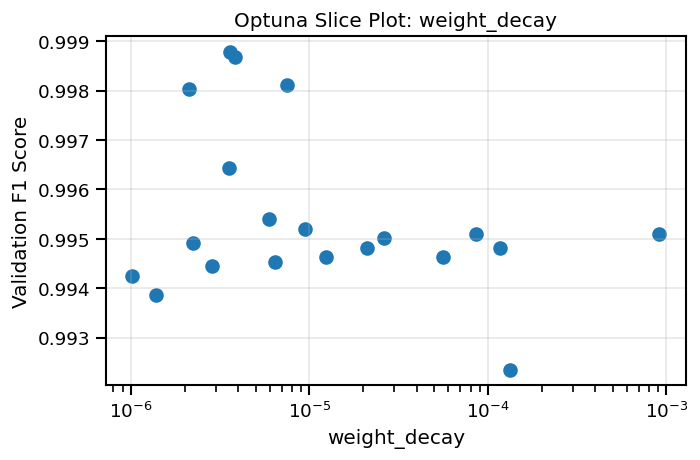

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_04_parallel_coordinate_like.png


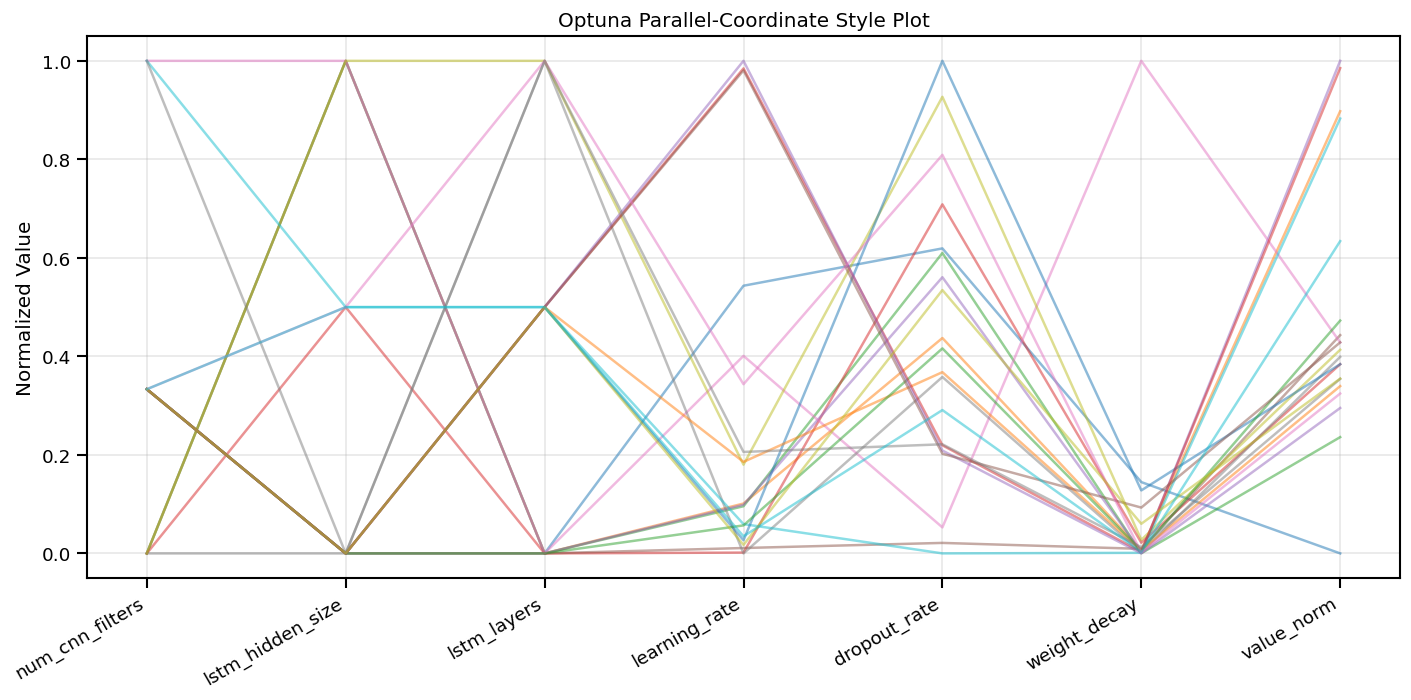

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/optuna_05_lr_vs_dropout_scatter.png


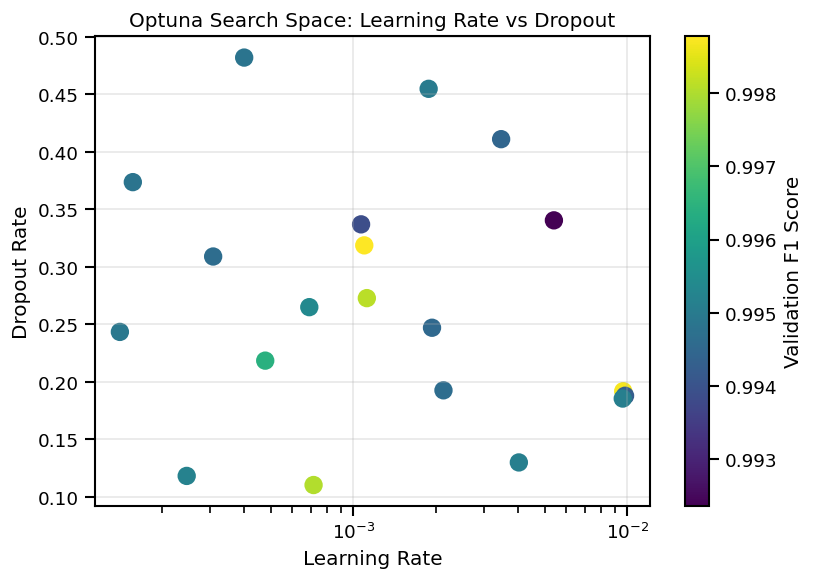

In [24]:
# ============================================================
# Reliable Matplotlib Optuna visualizations for Kaggle
# ============================================================

def plot_optuna_optimization_history(study):
    completed_trials = [t for t in study.trials if t.value is not None]
    trial_numbers = [t.number for t in completed_trials]
    values = [t.value for t in completed_trials]

    best_values = []
    current_best = -np.inf
    for v in values:
        current_best = max(current_best, v)
        best_values.append(current_best)

    plt.figure(figsize=(9, 5))
    plt.plot(trial_numbers, values, marker="o", label="Trial F1 Score")
    plt.plot(trial_numbers, best_values, marker="s", label="Best F1 So Far")
    plt.title("Bayesian Optimization History - CNN-LSTM")
    plt.xlabel("Trial")
    plt.ylabel("Validation F1 Score")
    plt.grid(True, alpha=0.3)
    plt.legend()
    save_fig("optuna_01_optimization_history.png")
    plt.show()


def plot_optuna_param_importance(study):
    try:
        importances = get_param_importances(study)
        imp_df = pd.DataFrame({
            "Parameter": list(importances.keys()),
            "Importance": list(importances.values())
        })

        display(imp_df)

        plt.figure(figsize=(8, 5))
        sns.barplot(data=imp_df, x="Importance", y="Parameter")
        plt.title("Optuna Hyperparameter Importance")
        plt.xlabel("Importance")
        plt.ylabel("Hyperparameter")
        save_fig("optuna_02_param_importance.png")
        plt.show()
    except Exception as e:
        print("Could not calculate parameter importance:", e)


def plot_optuna_slice_plots(study):
    records = []
    for t in study.trials:
        if t.value is None:
            continue
        row = {"trial": t.number, "value": t.value}
        row.update(t.params)
        records.append(row)

    df_trials = pd.DataFrame(records)
    display(df_trials.head())

    params = [c for c in df_trials.columns if c not in ["trial", "value"]]

    for param in params:
        plt.figure(figsize=(6, 4))
        if df_trials[param].dtype == "object":
            sns.stripplot(data=df_trials, x=param, y="value", jitter=True)
        else:
            plt.scatter(df_trials[param], df_trials["value"], s=60)
            if param == "learning_rate" or param == "weight_decay":
                plt.xscale("log")

        plt.title(f"Optuna Slice Plot: {param}")
        plt.xlabel(param)
        plt.ylabel("Validation F1 Score")
        plt.grid(True, alpha=0.3)
        save_fig(f"optuna_03_slice_{param}.png")
        plt.show()


def plot_optuna_parallel_coordinate_like(study):
    records = []
    for t in study.trials:
        if t.value is None:
            continue
        row = {"trial": t.number, "value": t.value}
        row.update(t.params)
        records.append(row)

    df_trials = pd.DataFrame(records)
    if df_trials.empty:
        print("No completed trials to plot.")
        return

    plot_df = df_trials.copy()
    params = [c for c in plot_df.columns if c not in ["trial", "value"]]

    # Encode categorical columns and normalize all axes to [0, 1]
    for col in params:
        if plot_df[col].dtype == "object":
            plot_df[col] = pd.factorize(plot_df[col])[0].astype(float)
        else:
            plot_df[col] = plot_df[col].astype(float)

        min_v = plot_df[col].min()
        max_v = plot_df[col].max()
        plot_df[col] = (plot_df[col] - min_v) / (max_v - min_v + 1e-8)

    value_min = plot_df["value"].min()
    value_max = plot_df["value"].max()
    plot_df["value_norm"] = (plot_df["value"] - value_min) / (value_max - value_min + 1e-8)

    x_labels = params + ["value_norm"]

    plt.figure(figsize=(12, 6))
    for _, row in plot_df.iterrows():
        y_values = [row[p] for p in params] + [row["value_norm"]]
        plt.plot(range(len(x_labels)), y_values, alpha=0.5)

    plt.xticks(range(len(x_labels)), x_labels, rotation=30, ha="right")
    plt.title("Optuna Parallel-Coordinate Style Plot")
    plt.ylabel("Normalized Value")
    plt.grid(True, alpha=0.3)
    save_fig("optuna_04_parallel_coordinate_like.png")
    plt.show()


def plot_optuna_lr_dropout_contour_like(study):
    records = []
    for t in study.trials:
        if t.value is None:
            continue
        if "learning_rate" in t.params and "dropout_rate" in t.params:
            records.append({
                "learning_rate": t.params["learning_rate"],
                "dropout_rate": t.params["dropout_rate"],
                "value": t.value
            })

    df_plot = pd.DataFrame(records)
    if df_plot.empty:
        print("No trial data available for learning-rate/dropout plot.")
        return

    plt.figure(figsize=(7, 5))
    sc = plt.scatter(
        df_plot["learning_rate"],
        df_plot["dropout_rate"],
        c=df_plot["value"],
        s=100
    )
    plt.xscale("log")
    plt.colorbar(sc, label="Validation F1 Score")
    plt.title("Optuna Search Space: Learning Rate vs Dropout")
    plt.xlabel("Learning Rate")
    plt.ylabel("Dropout Rate")
    plt.grid(True, alpha=0.3)
    save_fig("optuna_05_lr_vs_dropout_scatter.png")
    plt.show()


plot_optuna_optimization_history(study)
plot_optuna_param_importance(study)
plot_optuna_slice_plots(study)
plot_optuna_parallel_coordinate_like(study)
plot_optuna_lr_dropout_contour_like(study)

## 12. Train Final CNN-LSTM Model with Best Bayesian Hyperparameters

CNNLSTMClassifier(
  (cnn): Sequential(
    (0): Conv1d(82, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.31868411173731187, inplace=False)
    (4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
  )
  (lstm): LSTM(64, 50, batch_first=True)
  (classifier): Sequential(
    (0): Linear(in_features=50, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.31868411173731187, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 55010
Using best parameters: {'num_cnn_filters': 64, 'lstm_hidden_size': 50, 'lstm_layers': 1, 'learning_rate': 0.001096821720752952, 'dropout_rate': 0.31868411173731187, 'weight_decay': 3.5856126103453987e-06}
Bayesian CNN LSTM | Epoch 1/15 | Train Loss: 0.0198 | V

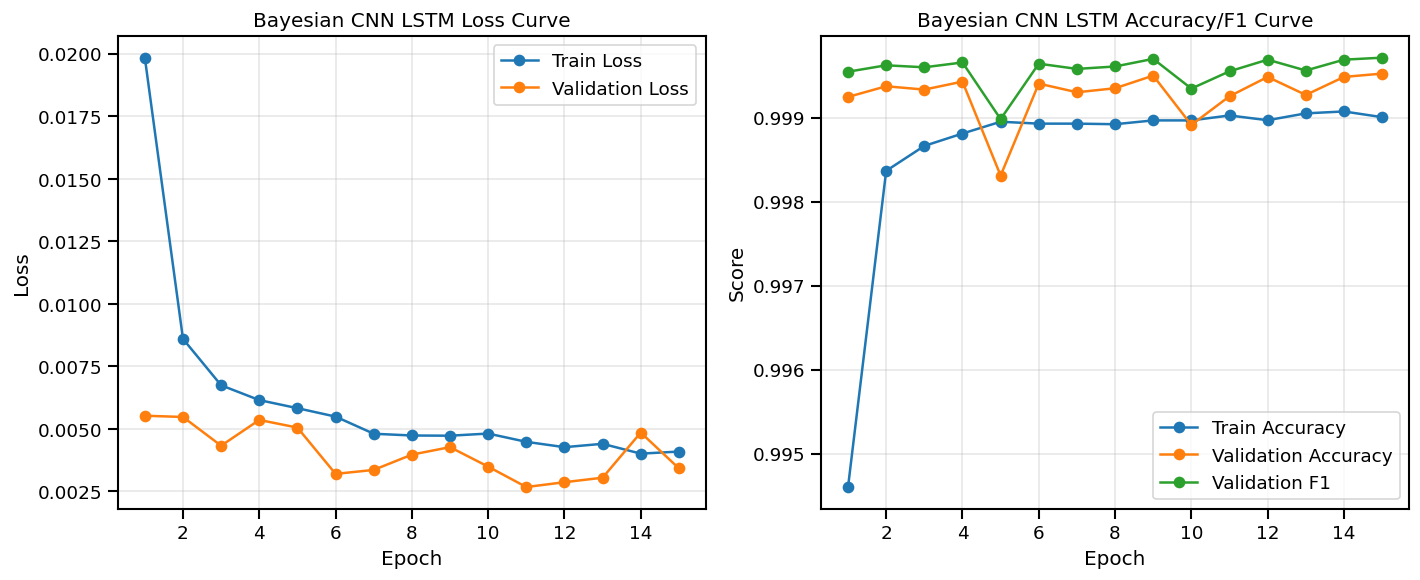

Saved Bayesian CNN-LSTM model: /kaggle/working/cicddos2019_thesis_outputs/models/bayesian_cnn_lstm_model.pth


In [25]:
# ============================================================
# Train final optimized CNN-LSTM model
# ============================================================

best_params = study.best_trial.params

cnn_lstm_model = CNNLSTMClassifier(
    num_features=num_features,
    num_cnn_filters=best_params["num_cnn_filters"],
    lstm_hidden_size=best_params["lstm_hidden_size"],
    lstm_layers=best_params["lstm_layers"],
    dropout_rate=best_params["dropout_rate"]
)

print(cnn_lstm_model)
print("Trainable parameters:", count_trainable_params(cnn_lstm_model))
print("Using best parameters:", best_params)

cnn_lstm_model, cnn_lstm_history = train_deep_model(
    model=cnn_lstm_model,
    model_name="Bayesian CNN LSTM",
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=FINAL_CNN_LSTM_EPOCHS,
    learning_rate=best_params["learning_rate"],
    weight_decay=best_params["weight_decay"]
)

plot_history(cnn_lstm_history, "Bayesian CNN LSTM")

torch.save(cnn_lstm_model.state_dict(), MODEL_DIR / "bayesian_cnn_lstm_model.pth")
print("Saved Bayesian CNN-LSTM model:", MODEL_DIR / "bayesian_cnn_lstm_model.pth")


Classification Report - Bayesian CNN-LSTM
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     10650
      Attack       1.00      1.00      1.00     52297

    accuracy                           1.00     62947
   macro avg       1.00      1.00      1.00     62947
weighted avg       1.00      1.00      1.00     62947

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/bayesian_cnn-lstm_confusion_matrix.png


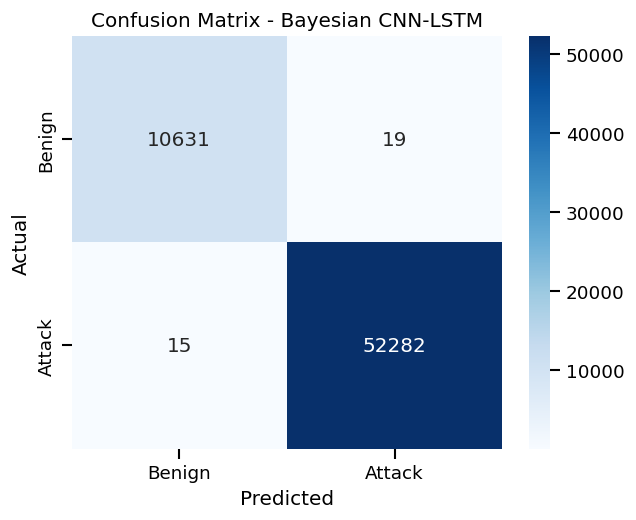

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/bayesian_cnn-lstm_roc_curve.png


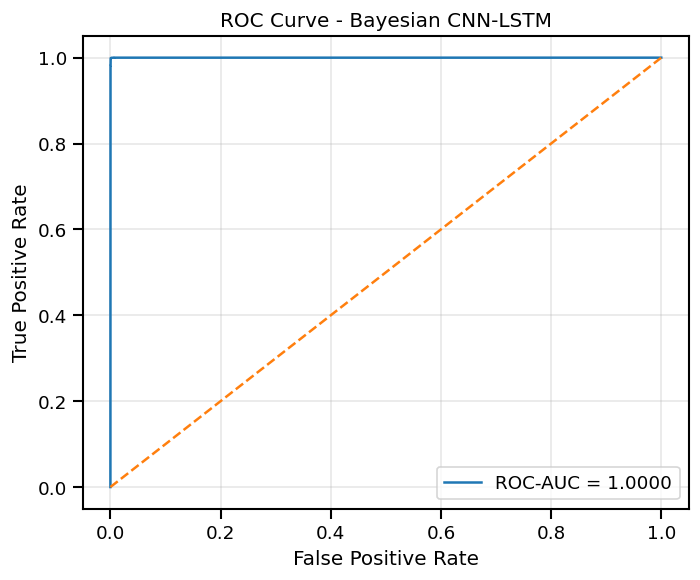

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/bayesian_cnn-lstm_precision_recall_curve.png


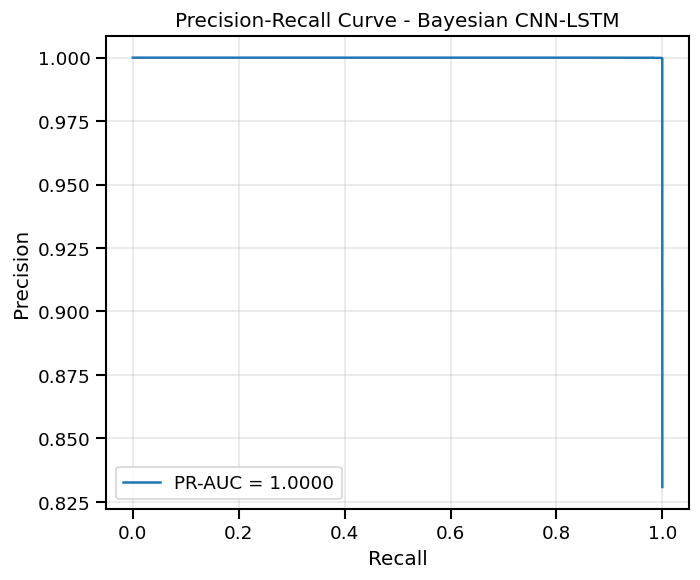

Bayesian CNN-LSTM test metrics:


,Model,Accuracy,Precision,Recall,F1 Score,MCC,ROC-AUC,PR-AUC
0,Bayesian CNN-LSTM,0.99946,0.999637,0.999713,0.999675,0.998078,0.999989,0.999998


In [26]:
# ============================================================
# Evaluate final optimized CNN-LSTM model
# ============================================================

cnn_lstm_results, cnn_lstm_y_true, cnn_lstm_y_pred, cnn_lstm_y_score = evaluate_deep_model(
    cnn_lstm_model,
    test_loader,
    model_name="Bayesian CNN-LSTM",
    make_plots=True
)

print("Bayesian CNN-LSTM test metrics:")
display(pd.DataFrame([cnn_lstm_results]))

## 13. Train Five Classical Machine Learning Models

These models do **not** use Bayesian optimization. They are benchmark models for comparison against the deep learning models.

In [27]:
# ============================================================
# Prepare data for ML benchmarks
# ============================================================

X_ml_train, y_ml_train = stratified_sample_arrays(
    X_train_scaled,
    y_train_np,
    ML_TRAIN_SAMPLE_SIZE,
    seed=SEED
)

X_ml_test = X_test_scaled
y_ml_test = y_test_np

print("ML training shape:", X_ml_train.shape)
print("ML test shape:", X_ml_test.shape)
print("ML training class distribution:", np.bincount(y_ml_train))
print("ML test class distribution:", np.bincount(y_ml_test))

ML training shape: (300000, 82)
ML test shape: (63046, 82)
ML training class distribution: [ 50737 249263]
ML test class distribution: [10663 52383]



Training ML model: Logistic Regression
Training time: 5.70 seconds
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97     10663
      Attack       1.00      0.99      0.99     52383

    accuracy                           0.99     63046
   macro avg       0.98      0.99      0.98     63046
weighted avg       0.99      0.99      0.99     63046

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/logistic_regression_confusion_matrix.png


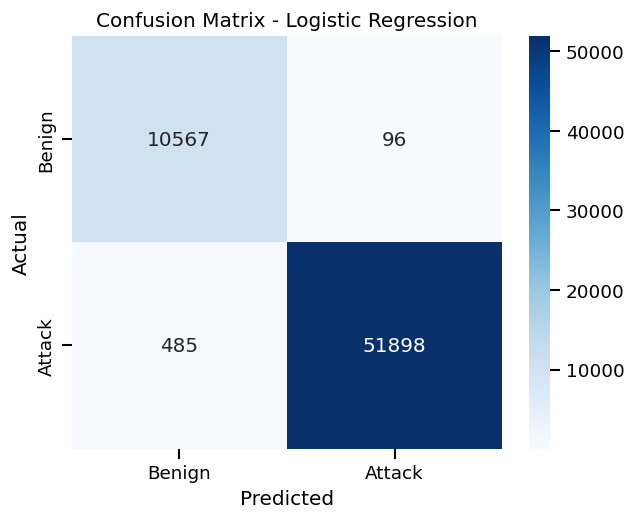

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/logistic_regression_roc_curve.png


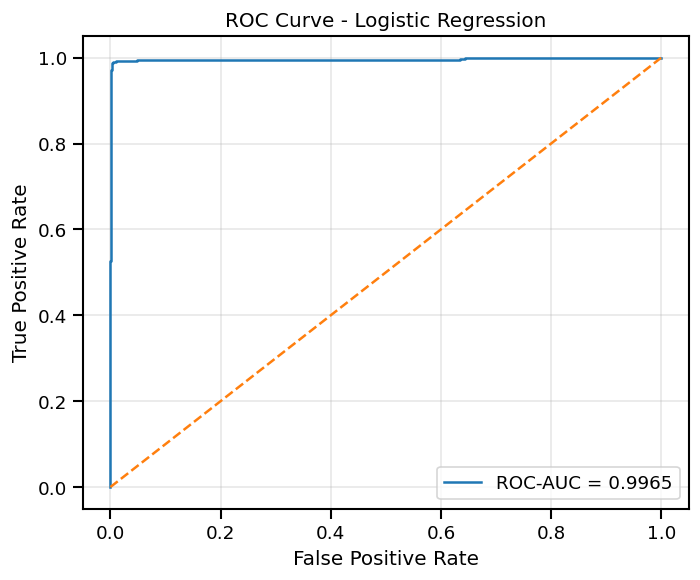

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/logistic_regression_precision_recall_curve.png


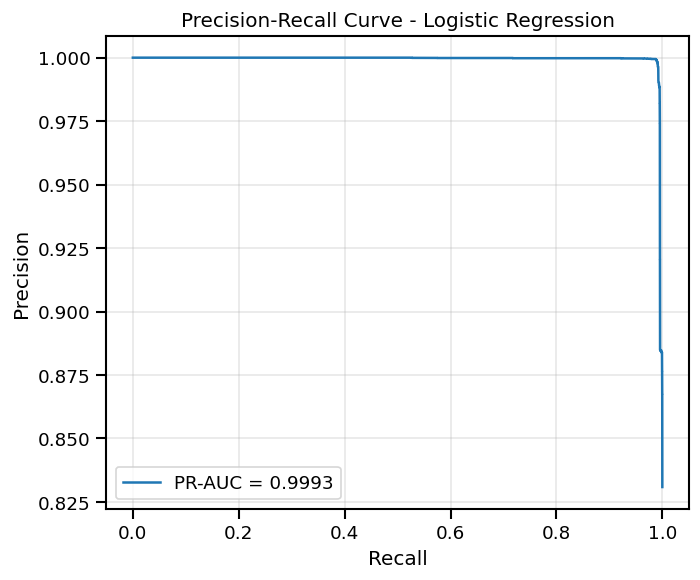

Saved model: /kaggle/working/cicddos2019_thesis_outputs/models/logistic_regression_model.joblib

Training ML model: Gaussian Naive Bayes
Training time: 0.22 seconds
              precision    recall  f1-score   support

      Benign       0.81      0.97      0.88     10663
      Attack       0.99      0.95      0.97     52383

    accuracy                           0.96     63046
   macro avg       0.90      0.96      0.93     63046
weighted avg       0.96      0.96      0.96     63046

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/gaussian_naive_bayes_confusion_matrix.png


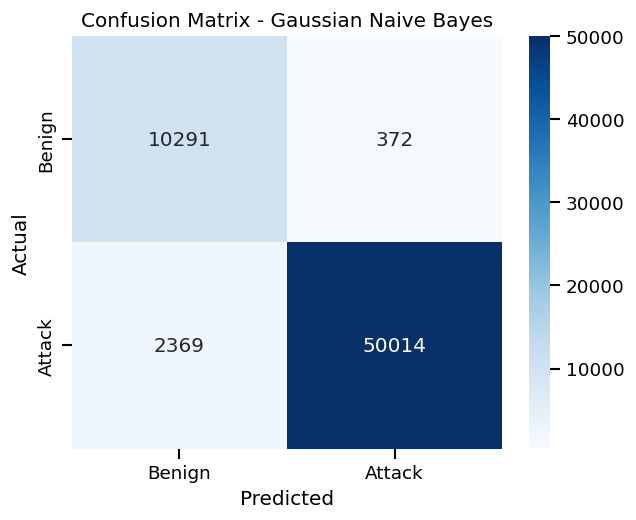

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/gaussian_naive_bayes_roc_curve.png


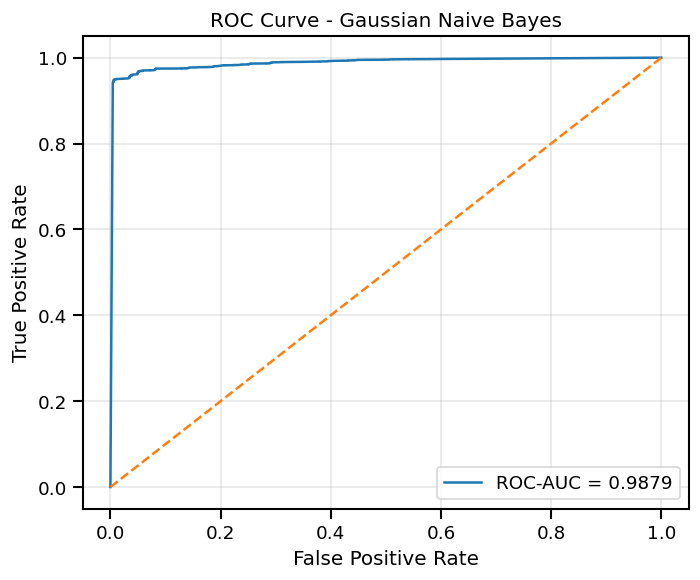

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/gaussian_naive_bayes_precision_recall_curve.png


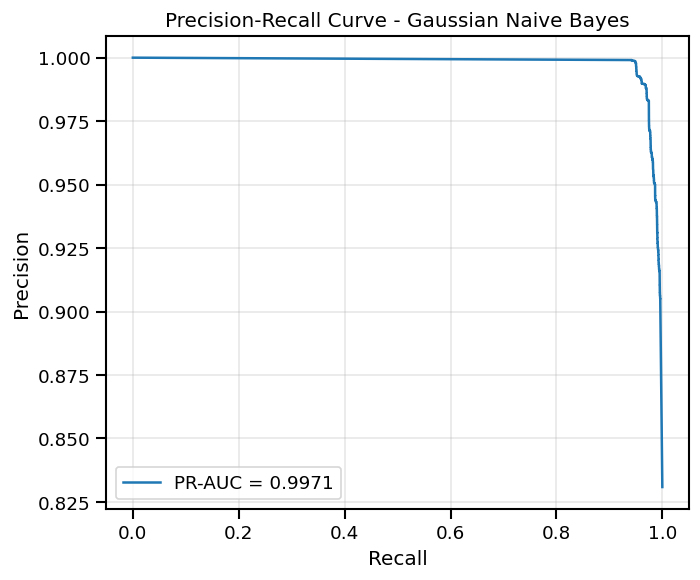

Saved model: /kaggle/working/cicddos2019_thesis_outputs/models/gaussian_naive_bayes_model.joblib

Training ML model: Decision Tree
Training time: 4.27 seconds
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     10663
      Attack       1.00      1.00      1.00     52383

    accuracy                           1.00     63046
   macro avg       1.00      1.00      1.00     63046
weighted avg       1.00      1.00      1.00     63046

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/decision_tree_confusion_matrix.png


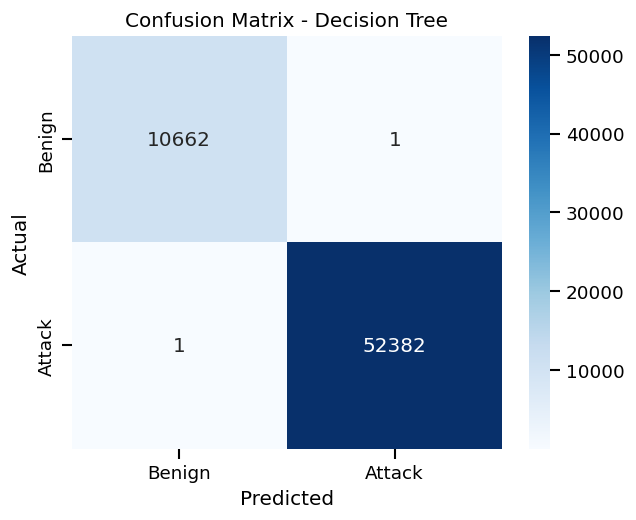

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/decision_tree_roc_curve.png


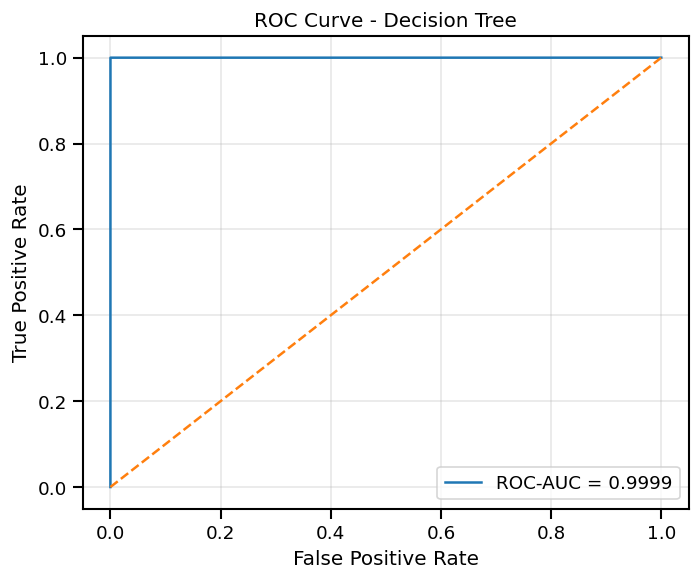

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/decision_tree_precision_recall_curve.png


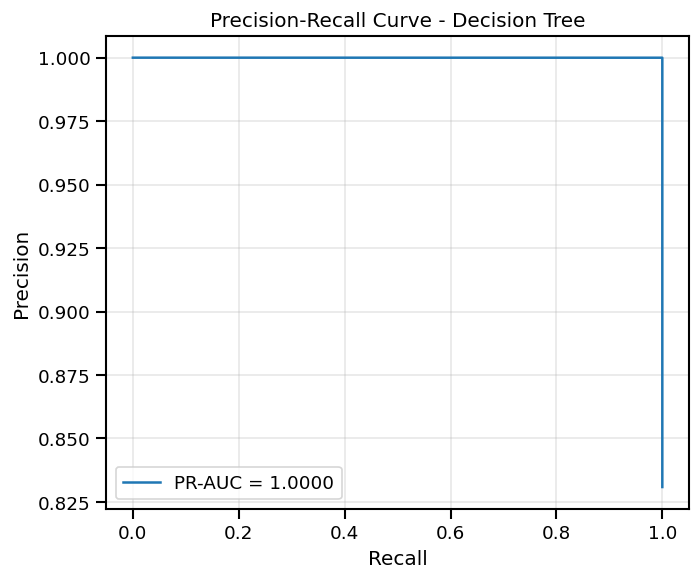

Saved model: /kaggle/working/cicddos2019_thesis_outputs/models/decision_tree_model.joblib

Training ML model: Random Forest
Training time: 21.16 seconds
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     10663
      Attack       1.00      1.00      1.00     52383

    accuracy                           1.00     63046
   macro avg       1.00      1.00      1.00     63046
weighted avg       1.00      1.00      1.00     63046

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/random_forest_confusion_matrix.png


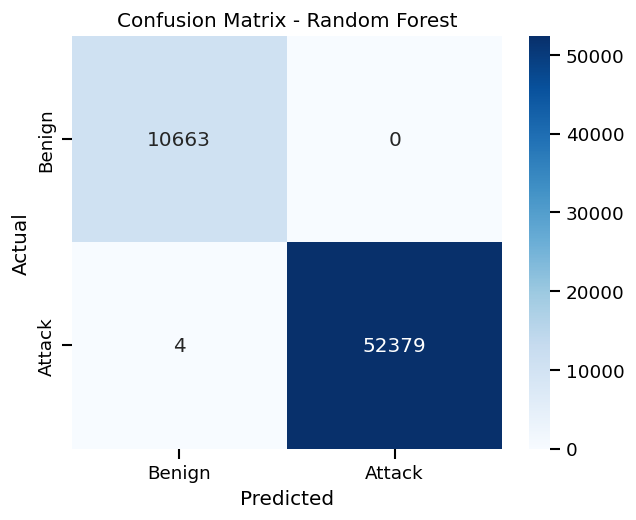

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/random_forest_roc_curve.png


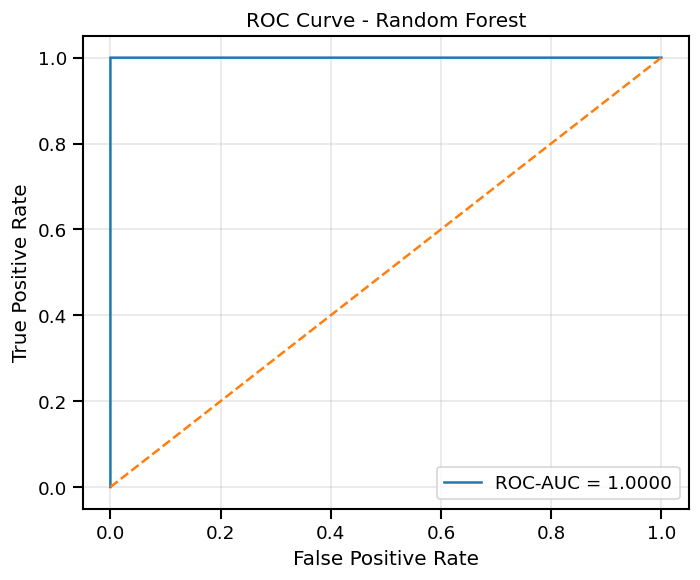

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/random_forest_precision_recall_curve.png


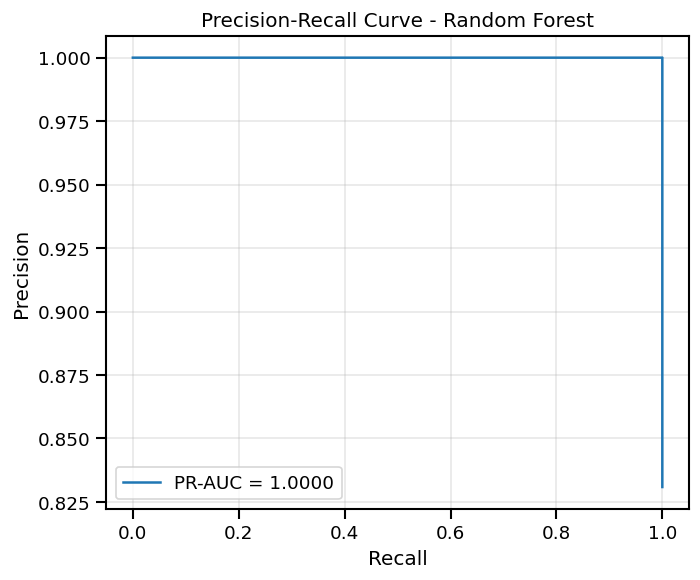

Saved model: /kaggle/working/cicddos2019_thesis_outputs/models/random_forest_model.joblib

Training ML model: Extra Trees
Training time: 15.54 seconds
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     10663
      Attack       1.00      1.00      1.00     52383

    accuracy                           1.00     63046
   macro avg       1.00      1.00      1.00     63046
weighted avg       1.00      1.00      1.00     63046

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/extra_trees_confusion_matrix.png


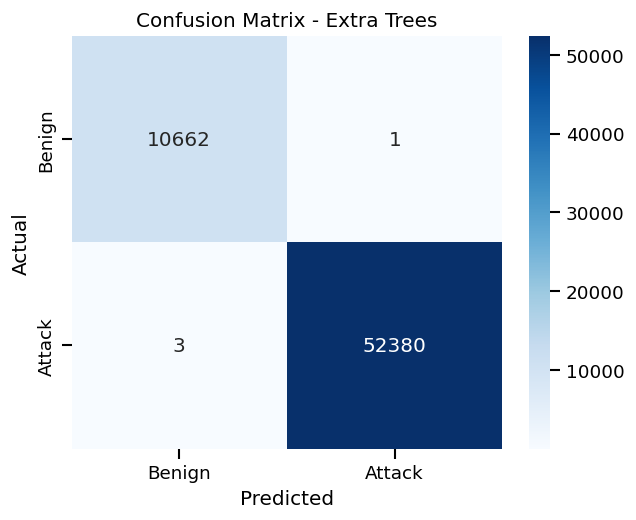

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/extra_trees_roc_curve.png


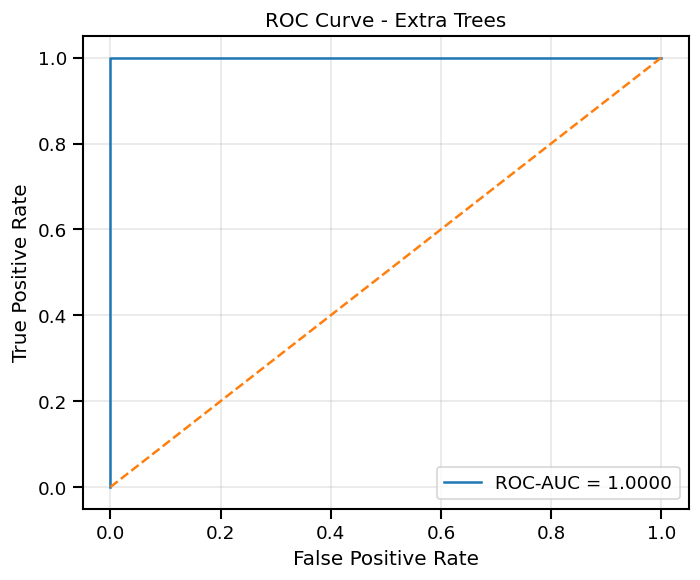

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/extra_trees_precision_recall_curve.png


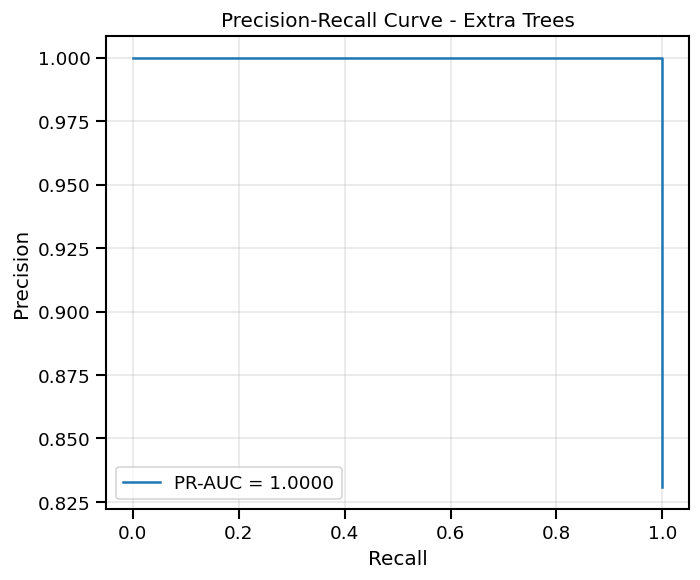

Saved model: /kaggle/working/cicddos2019_thesis_outputs/models/extra_trees_model.joblib


,Model,Accuracy,Precision,Recall,F1 Score,MCC,ROC-AUC,PR-AUC,Training Time (s)
0,Logistic Regression,0.990785,0.998154,0.990741,0.994434,0.967907,0.996491,0.999337,5.697430
1,Gaussian Naive Bayes,0.956524,0.992617,0.954775,0.973329,0.860792,0.987851,0.997113,0.218888
2,Decision Tree,0.999968,0.999981,0.999981,0.999981,0.999887,0.999944,0.999978,4.272066
3,Random Forest,0.999937,1.000000,0.999924,0.999962,0.999774,1.000000,1.000000,21.161815
4,Extra Trees,0.999937,0.999981,0.999943,0.999962,0.999774,1.000000,1.000000,15.543884


Saved ML results: /kaggle/working/cicddos2019_thesis_outputs/ml_model_results.csv


In [28]:
# ============================================================
# Train and evaluate five ML benchmark models
# ============================================================

ml_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    ),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    )
}

ml_results = []
ml_predictions = {}

for model_name, clf in ml_models.items():
    print("\n" + "=" * 80)
    print(f"Training ML model: {model_name}")
    print("=" * 80)

    start_time = time.time()
    clf.fit(X_ml_train, y_ml_train)
    train_time = time.time() - start_time

    y_pred = clf.predict(X_ml_test)
    y_score = get_positive_scores_from_estimator(clf, X_ml_test)

    metrics = calculate_metrics(y_ml_test, y_pred, y_score, model_name)
    metrics["Training Time (s)"] = train_time
    ml_results.append(metrics)

    ml_predictions[model_name] = {
        "y_true": y_ml_test,
        "y_pred": y_pred,
        "y_score": y_score
    }

    print(f"Training time: {train_time:.2f} seconds")
    print(classification_report(y_ml_test, y_pred, target_names=["Benign", "Attack"], zero_division=0))

    plot_confusion_matrix(y_ml_test, y_pred, model_name)
    plot_roc_curve(y_ml_test, y_score, model_name)
    plot_precision_recall_curve(y_ml_test, y_score, model_name)

    import joblib
    joblib.dump(clf, MODEL_DIR / f"{model_name.replace(' ', '_').lower()}_model.joblib")
    print("Saved model:", MODEL_DIR / f"{model_name.replace(' ', '_').lower()}_model.joblib")

ml_results_df = pd.DataFrame(ml_results)
display(ml_results_df)
ml_results_df.to_csv(OUTPUT_DIR / "ml_model_results.csv", index=False)
print("Saved ML results:", OUTPUT_DIR / "ml_model_results.csv")

## 14. Feature Importance from Tree-Based ML Models

,Feature,Importance
80,Inbound,6.792949e-01
0,Source Port,2.965572e-01
1,Destination Port,1.375791e-02
72,Active Mean,7.285783e-03
69,Init_Win_bytes_backward,1.456857e-03
68,Init_Win_bytes_forward,5.096879e-04
73,Active Std,4.884783e-04
40,Min Packet Length,3.254138e-04
30,Bwd IAT Max,7.159710e-05
66,Subflow Bwd Packets,5.048715e-05


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/decision_tree_feature_importance.png


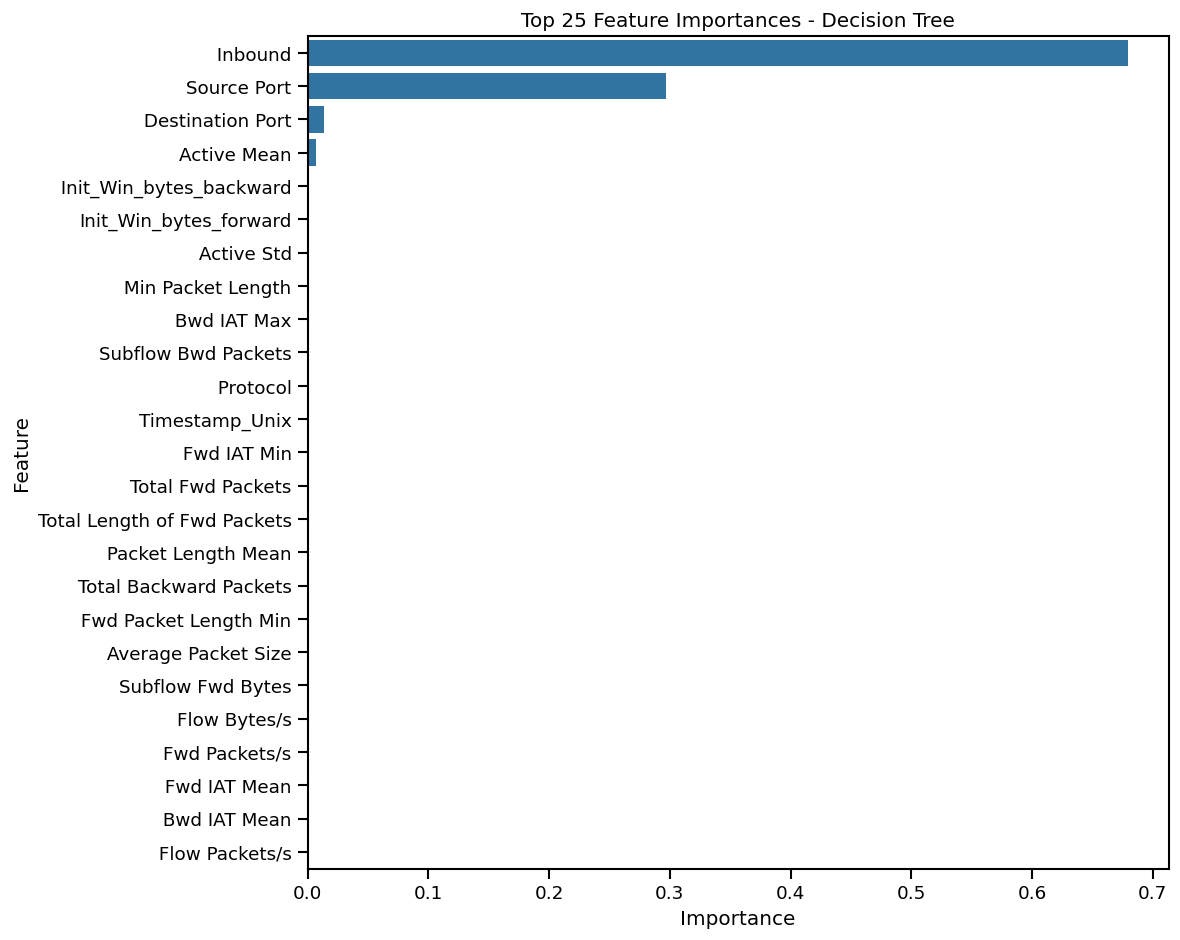

,Feature,Importance
1,Destination Port,0.123491
80,Inbound,0.111777
50,URG Flag Count,0.072540
40,Min Packet Length,0.052778
44,Packet Length Variance,0.052405
9,Fwd Packet Length Min,0.039686
0,Source Port,0.037013
55,Avg Fwd Segment Size,0.027949
10,Fwd Packet Length Mean,0.026603
39,Bwd Packets/s,0.026231


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/random_forest_feature_importance.png


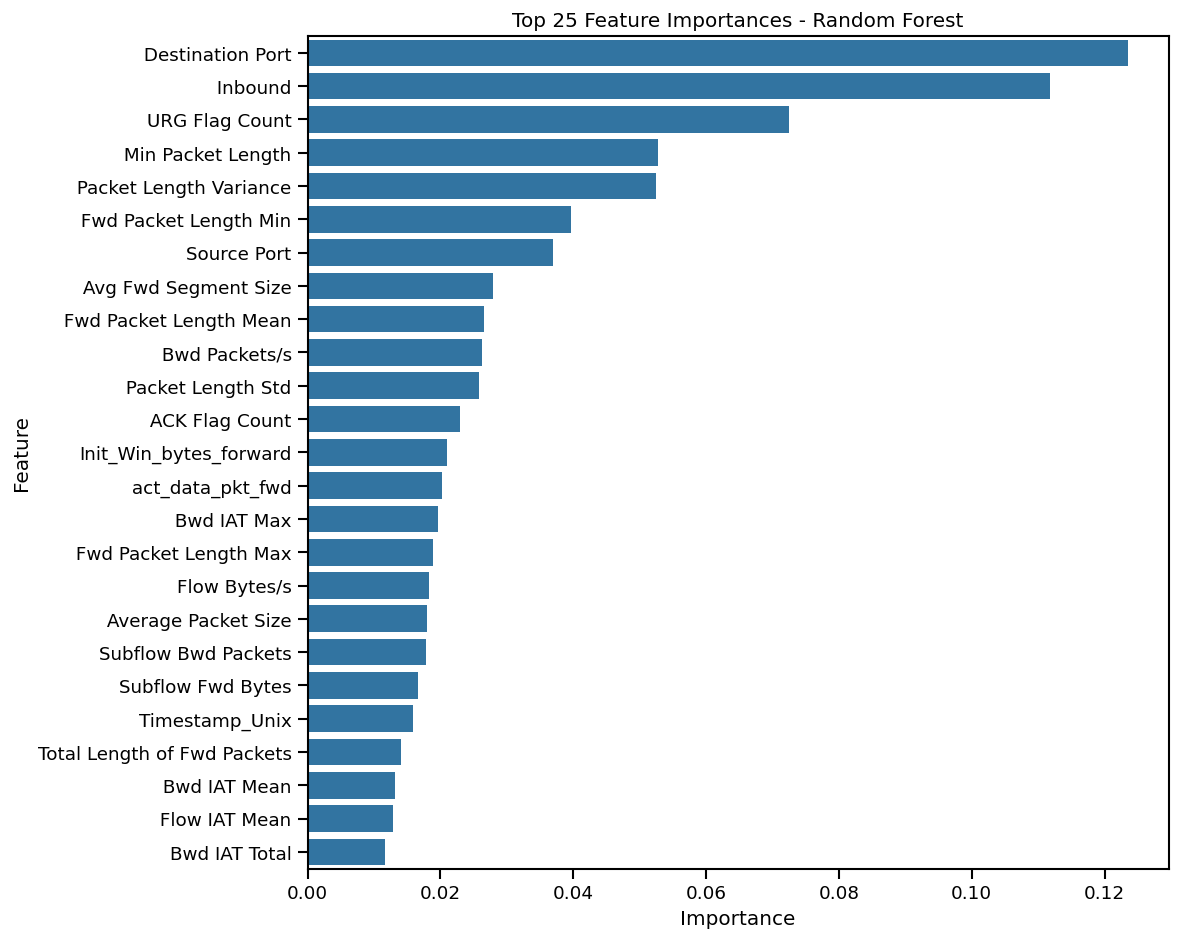

,Feature,Importance
80,Inbound,0.307545
50,URG Flag Count,0.109961
49,ACK Flag Count,0.066920
9,Fwd Packet Length Min,0.045068
40,Min Packet Length,0.043167
51,CWE Flag Count,0.041010
1,Destination Port,0.037314
10,Fwd Packet Length Mean,0.031901
42,Packet Length Mean,0.024840
2,Protocol,0.023046


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/extra_trees_feature_importance.png


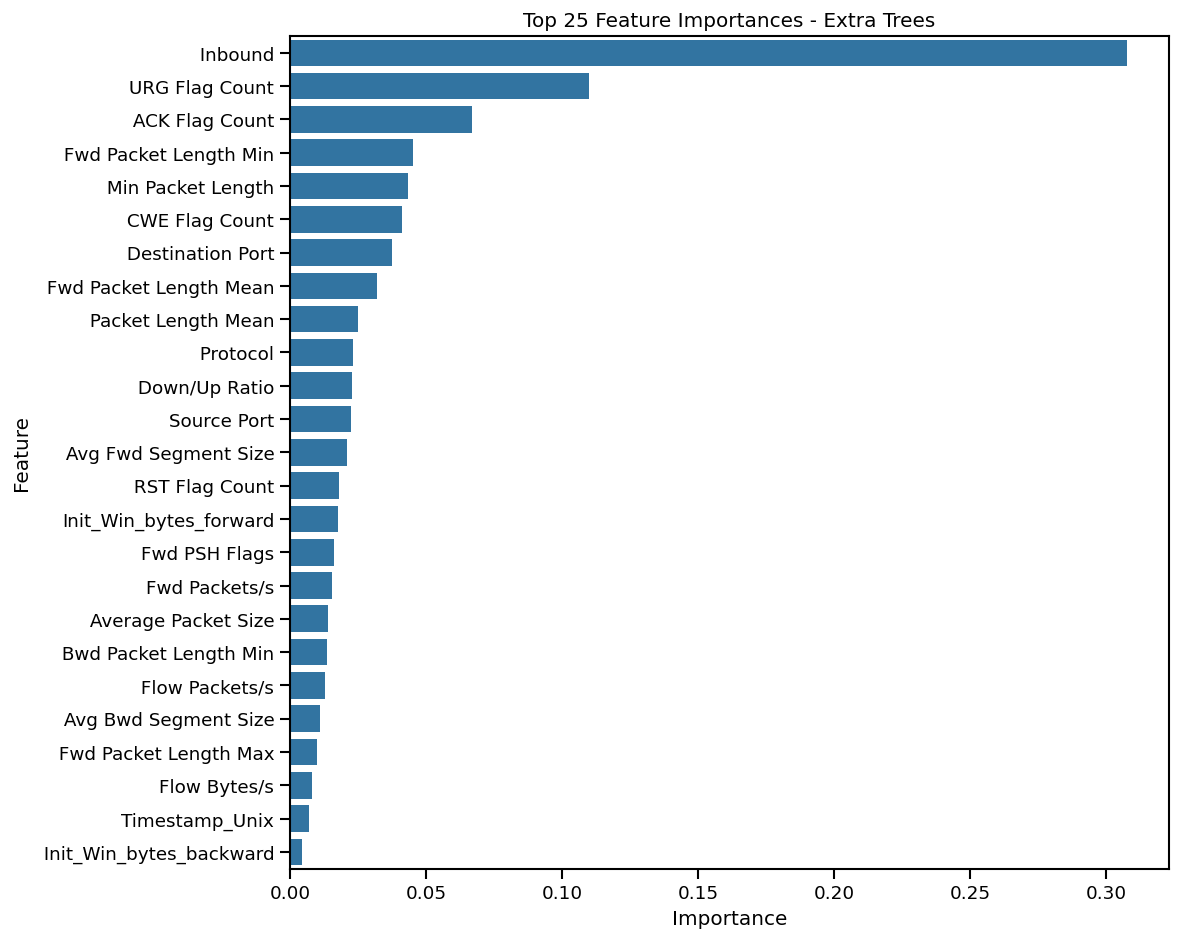

In [29]:
# ============================================================
# Feature importance plots for tree-based models
# ============================================================

feature_names = X_train.columns.tolist()

for model_name in ["Decision Tree", "Random Forest", "Extra Trees"]:
    clf = ml_models[model_name]

    if hasattr(clf, "feature_importances_"):
        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": clf.feature_importances_
        }).sort_values("Importance", ascending=False)

        display(importance_df.head(25))
        importance_df.to_csv(OUTPUT_DIR / f"{model_name.replace(' ', '_').lower()}_feature_importance.csv", index=False)

        plt.figure(figsize=(10, 8))
        top_imp = importance_df.head(25)
        sns.barplot(data=top_imp, x="Importance", y="Feature")
        plt.title(f"Top 25 Feature Importances - {model_name}")
        plt.xlabel("Importance")
        plt.ylabel("Feature")
        save_fig(f"{model_name.replace(' ', '_').lower()}_feature_importance.png")
        plt.show()

## 15. Final Comparison of All Models

In [30]:
# ============================================================
# Final model comparison table
# ============================================================

deep_results = [
    cnn_results,
    lstm_results,
    cnn_lstm_results
]

comparison_df = pd.DataFrame(deep_results + ml_results)

# Arrange columns
ordered_cols = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC",
    "ROC-AUC",
    "PR-AUC",
    "Training Time (s)"
]
for col in ordered_cols:
    if col not in comparison_df.columns:
        comparison_df[col] = np.nan

comparison_df = comparison_df[ordered_cols]
comparison_df = comparison_df.sort_values("F1 Score", ascending=False).reset_index(drop=True)

display(comparison_df)

comparison_df.to_csv(OUTPUT_DIR / "all_model_comparison.csv", index=False)
print("Saved final comparison:", OUTPUT_DIR / "all_model_comparison.csv")

,Model,Accuracy,Precision,Recall,F1 Score,MCC,ROC-AUC,PR-AUC,Training Time (s)
0,Decision Tree,0.999968,0.999981,0.999981,0.999981,0.999887,0.999944,0.999978,4.272066
1,Extra Trees,0.999937,0.999981,0.999943,0.999962,0.999774,1.000000,1.000000,15.543884
2,Random Forest,0.999937,1.000000,0.999924,0.999962,0.999774,1.000000,1.000000,21.161815
3,LSTM Only,0.999666,0.999847,0.999751,0.999799,0.998814,0.999999,1.000000,NaN
4,CNN Only,0.999476,0.999465,0.999904,0.999685,0.998134,0.999994,0.999999,NaN
5,Bayesian CNN-LSTM,0.999460,0.999637,0.999713,0.999675,0.998078,0.999989,0.999998,NaN
6,Logistic Regression,0.990785,0.998154,0.990741,0.994434,0.967907,0.996491,0.999337,5.697430
7,Gaussian Naive Bayes,0.956524,0.992617,0.954775,0.973329,0.860792,0.987851,0.997113,0.218888


Saved final comparison: /kaggle/working/cicddos2019_thesis_outputs/all_model_comparison.csv


Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/final_01_model_comparison_all_metrics.png


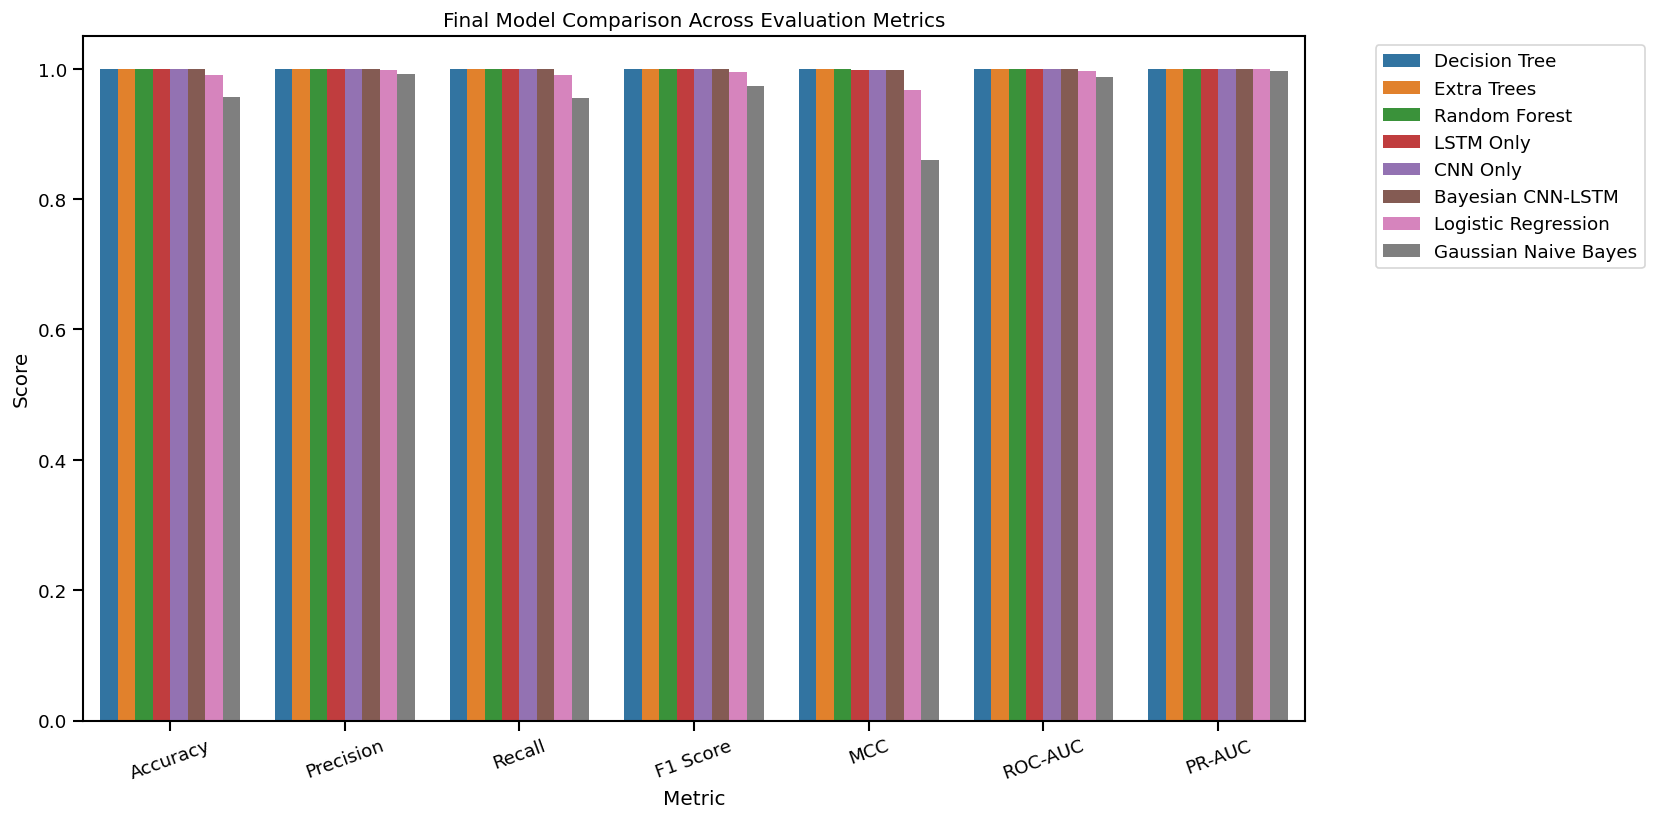

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/final_02_model_ranking_by_f1.png


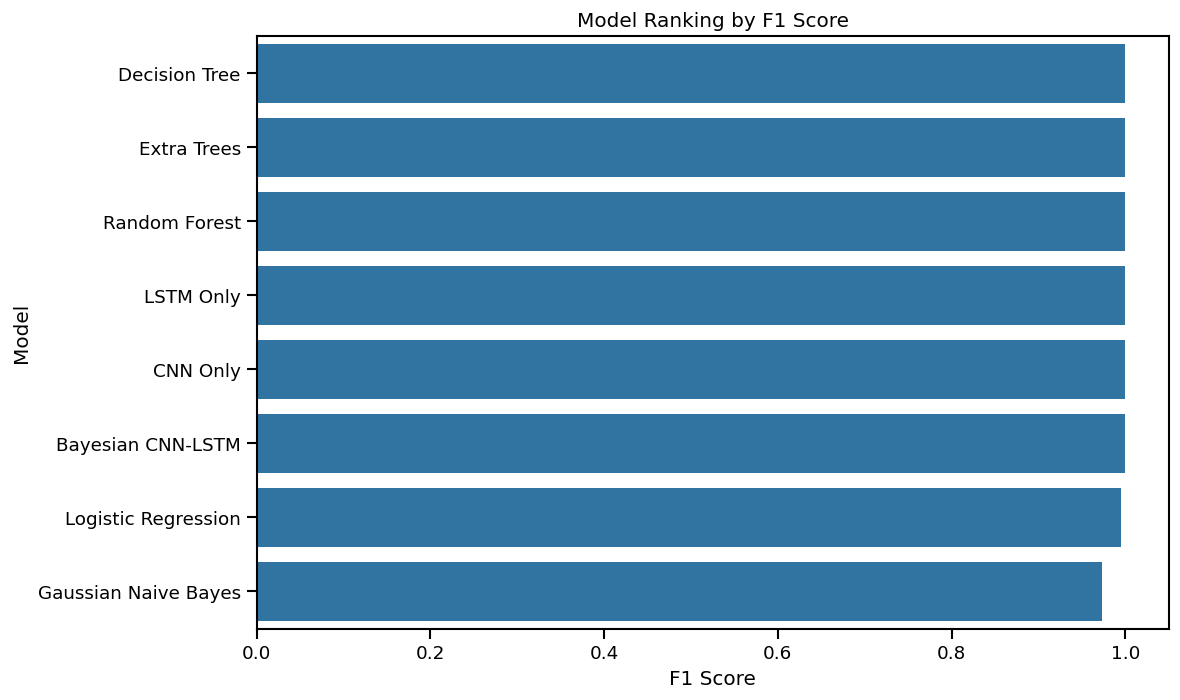

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/final_03_model_ranking_by_roc_auc.png


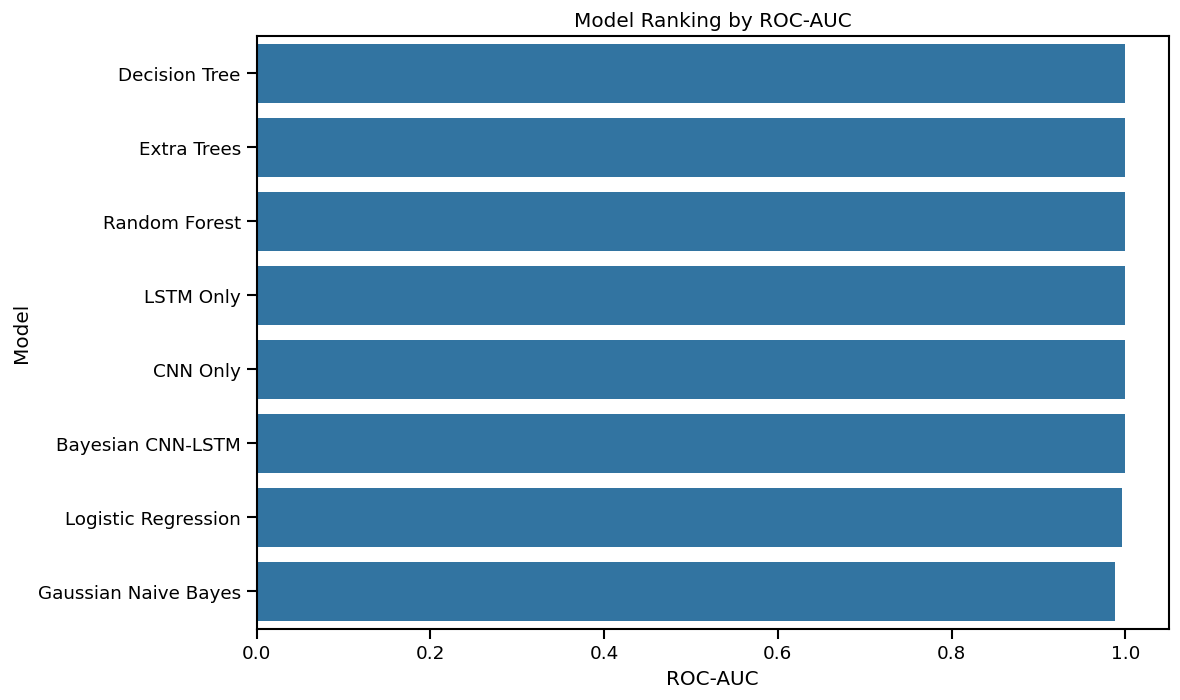

In [31]:
# ============================================================
# Final comparison bar plots
# ============================================================

metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score", "MCC", "ROC-AUC", "PR-AUC"]

melted = comparison_df.melt(
    id_vars="Model",
    value_vars=metric_cols,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))
sns.barplot(data=melted, x="Metric", y="Score", hue="Model")
plt.title("Final Model Comparison Across Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
save_fig("final_01_model_comparison_all_metrics.png")
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_df, x="F1 Score", y="Model")
plt.title("Model Ranking by F1 Score")
plt.xlabel("F1 Score")
plt.ylabel("Model")
plt.xlim(0, 1.05)
save_fig("final_02_model_ranking_by_f1.png")
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_df, x="ROC-AUC", y="Model")
plt.title("Model Ranking by ROC-AUC")
plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.xlim(0, 1.05)
save_fig("final_03_model_ranking_by_roc_auc.png")
plt.show()

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/final_04_combined_roc_curves.png


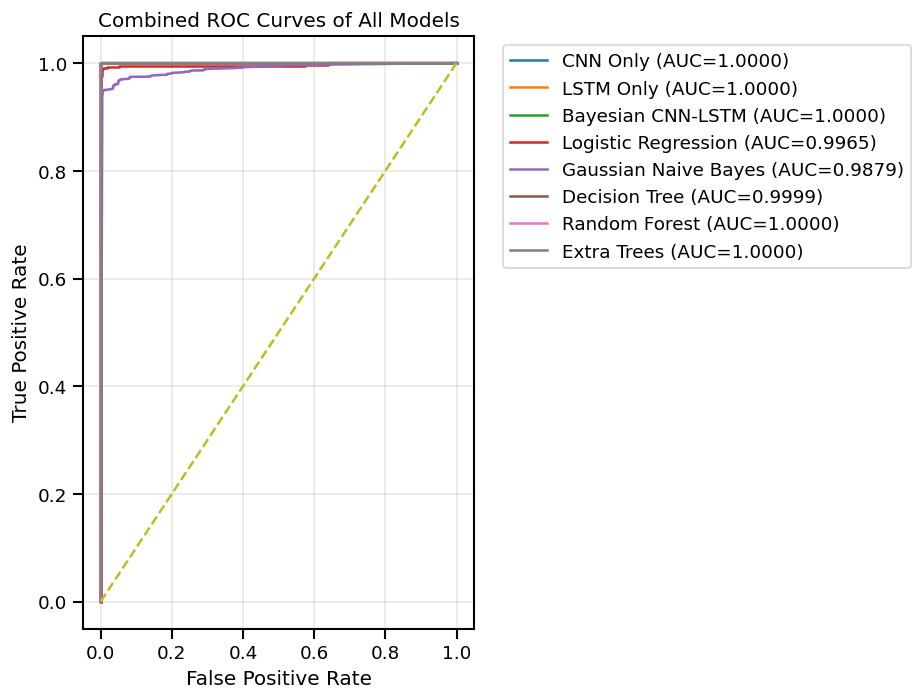

In [32]:
# ============================================================
# Combined ROC curves for thesis comparison
# ============================================================

plt.figure(figsize=(8, 6))

# Deep models
for name, y_true, y_score in [
    ("CNN Only", cnn_y_true, cnn_y_score),
    ("LSTM Only", lstm_y_true, lstm_y_score),
    ("Bayesian CNN-LSTM", cnn_lstm_y_true, cnn_lstm_y_score),
]:
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc_value = roc_auc_score(y_true, y_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.4f})")

# ML models
for name, preds in ml_predictions.items():
    fpr, tpr, _ = roc_curve(preds["y_true"], preds["y_score"])
    auc_value = roc_auc_score(preds["y_true"], preds["y_score"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("Combined ROC Curves of All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
save_fig("final_04_combined_roc_curves.png")
plt.show()

Saved figure: /kaggle/working/cicddos2019_thesis_outputs/figures/final_05_combined_precision_recall_curves.png


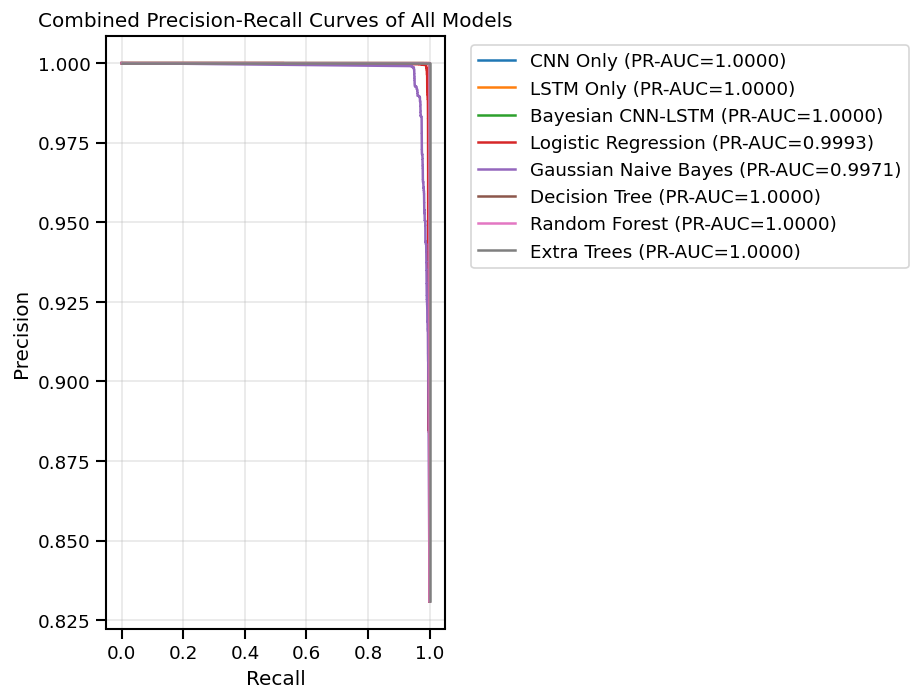

In [33]:
# ============================================================
# Combined Precision-Recall curves for thesis comparison
# ============================================================

plt.figure(figsize=(8, 6))

# Deep models
for name, y_true, y_score in [
    ("CNN Only", cnn_y_true, cnn_y_score),
    ("LSTM Only", lstm_y_true, lstm_y_score),
    ("Bayesian CNN-LSTM", cnn_lstm_y_true, cnn_lstm_y_score),
]:
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    pr_auc = average_precision_score(y_true, y_score)
    plt.plot(recall, precision, label=f"{name} (PR-AUC={pr_auc:.4f})")

# ML models
for name, preds in ml_predictions.items():
    precision, recall, _ = precision_recall_curve(preds["y_true"], preds["y_score"])
    pr_auc = average_precision_score(preds["y_true"], preds["y_score"])
    plt.plot(recall, precision, label=f"{name} (PR-AUC={pr_auc:.4f})")

plt.title("Combined Precision-Recall Curves of All Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
save_fig("final_05_combined_precision_recall_curves.png")
plt.show()

## 16. Thesis Interpretation Helper Outputs

This section prints concise thesis-friendly interpretation points based on the final results.

In [34]:
# ============================================================
# Automatic thesis-friendly summary
# ============================================================

best_model_row = comparison_df.iloc[0]

print("=" * 100)
print("THESIS SUMMARY")
print("=" * 100)

print(f"Best model based on F1 Score: {best_model_row['Model']}")
print(f"Accuracy:  {best_model_row['Accuracy']:.4f}")
print(f"Precision: {best_model_row['Precision']:.4f}")
print(f"Recall:    {best_model_row['Recall']:.4f}")
print(f"F1 Score:  {best_model_row['F1 Score']:.4f}")
print(f"ROC-AUC:   {best_model_row['ROC-AUC']:.4f}")
print(f"PR-AUC:    {best_model_row['PR-AUC']:.4f}")

print("\nWhy CNN-LSTM is included:")
print("- CNN-only model checks whether local traffic-pattern extraction alone is enough.")
print("- LSTM-only model checks whether sequential dependency modeling alone is enough.")
print("- CNN-LSTM combines both: CNN extracts local feature patterns, and LSTM models temporal behavior across sequences.")
print("- Bayesian optimization searches the CNN-LSTM hyperparameter space instead of manually selecting parameters.")

print("\nSaved outputs:")
print("Figures:", FIG_DIR)
print("Models:", MODEL_DIR)
print("Comparison CSV:", OUTPUT_DIR / "all_model_comparison.csv")

THESIS SUMMARY
Best model based on F1 Score: Decision Tree
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
ROC-AUC:   0.9999
PR-AUC:    1.0000

Why CNN-LSTM is included:
- CNN-only model checks whether local traffic-pattern extraction alone is enough.
- LSTM-only model checks whether sequential dependency modeling alone is enough.
- CNN-LSTM combines both: CNN extracts local feature patterns, and LSTM models temporal behavior across sequences.
- Bayesian optimization searches the CNN-LSTM hyperparameter space instead of manually selecting parameters.

Saved outputs:
Figures: /kaggle/working/cicddos2019_thesis_outputs/figures
Models: /kaggle/working/cicddos2019_thesis_outputs/models
Comparison CSV: /kaggle/working/cicddos2019_thesis_outputs/all_model_comparison.csv


In [35]:
# ============================================================
# Zip all thesis outputs for download from Kaggle
# ============================================================

import shutil

zip_path = "/kaggle/working/cicddos2019_thesis_outputs.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(
    base_name="/kaggle/working/cicddos2019_thesis_outputs",
    format="zip",
    root_dir=OUTPUT_DIR
)

print("Zipped output file created:")
print(zip_path)

!ls -lh /kaggle/working/cicddos2019_thesis_outputs.zip

Zipped output file created:
/kaggle/working/cicddos2019_thesis_outputs.zip
-rw-r--r-- 1 root root 12M Jun  3 17:03 /kaggle/working/cicddos2019_thesis_outputs.zip
